# Лабораторна робота №3. Побудова рішення розпізнавання тексту з застосуванням ШІ

**Варіант 5.**
* Відкритий набір: Perestoroha OCR — рукописні картки з цитатами (Львів, 1605–1606), `lang-uk/perestoroha-ocr`.
* Інструменти: **T** — Tesseract 5 (`ukr+eng`), **V** — VLM Qwen2.5-VL 7B локально через Ollama.
* Чинник деградації: якість JPEG, %: 100, 50, 30, 20, 10, 5.
* Особливість: чи «осучаснює» VLM правопис — окремий CER для історичних графем.
* Власні дані: фото рукописного тексту з дореформеними літерами + рукописна сторінка з «Інститутки».
* Текст для синтетичного набору: Марко Вовчок, «Інститутка» (Вікіджерела, видання 1929 р.).

## 1. Імпорт бібліотек і персональні параметри

In [1]:
import os, re, io, json, time, glob, hashlib, unicodedata, warnings, platform, textwrap
from collections import Counter
from datetime import datetime, date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import pytesseract
import ollama
from PIL import Image, ImageDraw, ImageFont, ImageOps, ExifTags
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

# ---- персональні параметри ----
STUDENT = "Кормило В. В."
GROUP = "ПЗ-47"
VARIANT = 5
STUDENT_ID = 49                 # останні 3 цифри залікової книжки: 049
SEED = 1000 * VARIANT + STUDENT_ID

# окремі генератори для окремих етапів: зміна одного етапу не зсуває випадкові числа інших
rng_data = np.random.default_rng(SEED)        # вибір речень, розмір шрифту
rng_open = np.random.default_rng(SEED + 1)    # вибір карток відкритого набору
rng_boot = np.random.default_rng(SEED + 2)    # бутстреп
rng_plot = np.random.default_rng(SEED + 3)    # розкид точок на графіках
rng_extra = np.random.default_rng(SEED + 4)   # додаткова вибірка (питання 2)

pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
TESS_LANG = "ukr+eng"
VLM_MODEL = "qwen2.5vl:7b"
FORCE = False   # True — перерахувати розпізнавання, ігноруючи кеш у results/

FONTS = ["C:/Windows/Fonts/arial.ttf", "C:/Windows/Fonts/times.ttf",
         "C:/Windows/Fonts/calibri.ttf", "C:/Windows/Fonts/georgia.ttf"]

for d in ["data/synth", "data/open", "figures", "results", "my_photos", "tmp"]:
    os.makedirs(d, exist_ok=True)

plt.rcParams["figure.dpi"] = 100


def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)


def savefig(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


# cv2.imread/imwrite у Windows не відкривають шляхи з кирилицею — читаємо через numpy
def imread_gray(path):
    return cv2.imdecode(np.fromfile(path, np.uint8), cv2.IMREAD_GRAYSCALE)


def imread_color(path):
    return cv2.imdecode(np.fromfile(path, np.uint8), cv2.IMREAD_COLOR)


def imwrite(path, img):
    ok, enc = cv2.imencode(os.path.splitext(path)[1], img)
    enc.tofile(path)


def sha256_file(path, n=16):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()[:n]


TESS_VERSION = str(pytesseract.get_tesseract_version())
VLM_DIGEST = next((m.digest for m in ollama.list().models if m.model == VLM_MODEL), None)
print("SEED =", SEED)
print("Python", platform.python_version(), "| Tesseract", TESS_VERSION,
      "| мови:", pytesseract.get_languages(config=""))
print("VLM:", VLM_MODEL, "digest", (VLM_DIGEST or "?")[:12])

SEED = 5049
Python 3.14.2 | Tesseract 5.5.3.20260724 | мови: ['eng', 'ukr']
VLM: qwen2.5vl:7b digest 5ced39dfa4ba


## 2. Синтетичний набір з еталонною розміткою

40 речень з «Інститутки» (довжина 20–70 символів), кожне відтворене одним із чотирьох шрифтів
Windows з кирилицею розміром 22–35 px і збережене на 6 рівнях якості JPEG. Спотворене
зображення зберігається у PNG (без втрат), тобто артефакти JPEG фіксуються в пікселях.

In [2]:
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]

N_LINES = 40
lines = [str(s) for s in rng_data.choice(corpus, size=N_LINES, replace=False)]


def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)


def degrade(img, kind, level, rng=None):
    out = img.astype(np.float32)
    if kind == "noise" and level > 0:          # σ гаусового шуму
        out = out + rng.normal(0, level, out.shape)
    elif kind == "blur" and level > 0:         # σ гаусового розмиття
        out = cv2.GaussianBlur(out, (0, 0), level)
    elif kind == "jpeg" and level < 100:       # якість JPEG, %
        ok, enc = cv2.imencode(".jpg", out.astype(np.uint8),
                               [cv2.IMWRITE_JPEG_QUALITY, int(level)])
        out = cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE).astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


FACTOR, LEVELS = "jpeg", [100, 50, 30, 20, 10, 5]


def build_synth(texts, prefix, rng, levels, size_range=(22, 36), folder="data/synth"):
    recs = []
    for i, text in enumerate(texts):
        font = FONTS[i % len(FONTS)]
        size = int(rng.integers(*size_range))
        clean = render_line(text, font, size=size)
        for lvl in levels:
            path = f"{folder}/{prefix}{i:03d}_{FACTOR}_{lvl}.png"
            imwrite(path, degrade(clean, FACTOR, lvl))
            recs.append({"id": i, "level": lvl, "path": path, "gt": text,
                         "font": os.path.basename(font), "size": size})
    return pd.DataFrame(recs)


ds = build_synth(lines, "", rng_data, LEVELS)
ds.to_csv("data/synth/ground_truth.csv", index=False, lineterminator="\n")
GT_SHA = sha256_file("data/synth/ground_truth.csv")
print("Записів:", len(ds), "| рядків:", N_LINES, "| рівнів:", len(LEVELS), "| SHA-256 еталону:", GT_SHA)
print(ds.drop_duplicates("id")[["id", "font", "size", "gt"]].head(8).to_string())

Записів: 240 | рядків: 40 | рівнів: 6 | SHA-256 еталону: 20e6f0cd55cc33a2
    id         font  size                                                              gt
0    0    arial.ttf    24                       Дівчата вже мене дожидають: — А що, Усте?
6    1    times.ttf    28                             Я на рундуці сіла, як на гробовищі.
12   2  calibri.ttf    26  На вибір дають, на людськую волю: хоч утопись, хоч так загинь.
18   3  georgia.ttf    34                                      На дворі візок запрягають.
24   4    arial.ttf    31                                    Пані від його відвертається.
30   5    times.ttf    25                    відказала, пані, вибігла і дверима грукнула.
36   6  calibri.ttf    25                відказала Катря, хоч мене живцем із'їджте тепер!
42   7  georgia.ttf    34                                          Що ти накоїла, ледащо?


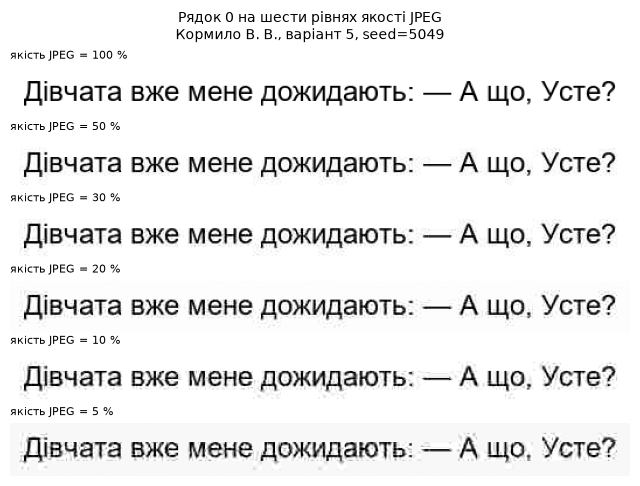

In [3]:
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 0.9 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    img = imread_gray(f"data/synth/000_{FACTOR}_{lvl}.png")
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"якість JPEG = {lvl} %", fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Рядок 0 на шести рівнях якості JPEG\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
savefig(fig, "fig0_samples")

## 3. Відкритий набір Perestoroha OCR

Набір містить 430 карток (train 278, validation 122, test 30). Кожна картка — рукописна
цитата старо-українського тексту 1605–1606 рр. з підписом джерела. Модель не донавчається,
тому всі три частини об'єднано і випадково (генератор SEED+1) обрано 100 карток.
Ідентифікатори збережено в `data/open/perestoroha_ids.csv`.

In [4]:
from datasets import load_dataset, Image as HFImage

hf = load_dataset("lang-uk/perestoroha-ocr").cast_column("image", HFImage(decode=False))
pool = [(split, i) for split in ["train", "validation", "test"] for i in range(len(hf[split]))]
N_OPEN = 100
sel = sorted(rng_open.choice(len(pool), size=N_OPEN, replace=False).tolist())

open_rows = []
for k, idx in enumerate(sel):
    split, i = pool[idx]
    x = hf[split][i]
    raw = x["image"]["bytes"]                      # оригінальні байти зображення, без перекодування
    ext = ".jpg" if raw[:3] == b"\xff\xd8\xff" else ".png"
    path = f"data/open/card_{k:03d}{ext}"
    if not os.path.exists(path):
        with open(path, "wb") as f:
            f.write(raw)
    open_rows.append({"k": k, "split": split, "index": i, "id": x["id"], "path": path,
                      "gt": x["transcription"].replace("\r\n", "\n"),
                      "reference": x["source_reference"]})
ods = pd.DataFrame(open_rows)
ods.to_csv("data/open/perestoroha_ids.csv", index=False, lineterminator="\n")
print("Карток:", len(ods), "| SHA-256 списку:", sha256_file("data/open/perestoroha_ids.csv"))
print(ods.split.value_counts().to_dict())
print("Середня довжина еталону, символів:", round(ods["gt"].str.len().mean(), 1))

Using the latest cached version of the dataset since lang-uk/perestoroha-ocr couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at C:\Users\Vitaliy\.cache\huggingface\datasets\lang-uk___perestoroha-ocr\default\0.0.0\c7af19760e731a130e963eae29f3290c21296f3f (last modified on Mon Nov  9 19:06:23 2026).


Карток: 100 | SHA-256 списку: 59757d3af3bca394
{'train': 62, 'validation': 29, 'test': 9}
Середня довжина еталону, символів: 195.6


**Історичні графеми.** Літери, яких немає в сучасному українському алфавіті: ѣ (ять), ъ (єр),
ы (єри), ѳ (фіта), ѵ (іжиця), э. Літери є та і в карток трапляються, але вони є й у сучасній
абетці, тому в окрему групу не входять.

Історичні графеми в еталоні 100 карток: {'ъ': 301, 'ы': 314, 'ѣ': 223, 'ѳ': 2, 'ѵ': 1}
Частка історичних графем серед непробільних символів: 5.1%
Карток з хоча б однією історичною графемою: 99%


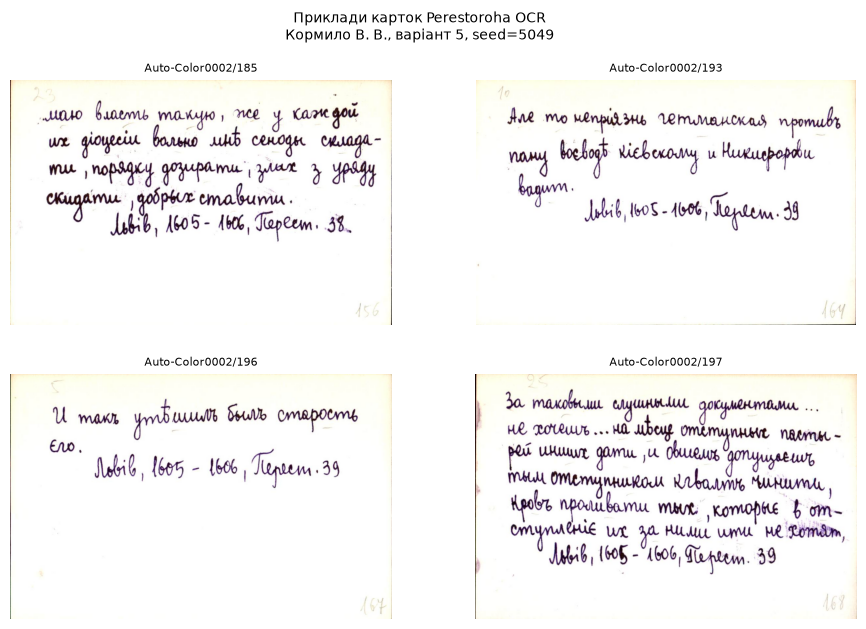

In [5]:
HIST = set("ѣъыѳѵэѢЪЫѲѴЭ")
cnt_all = Counter("".join(ods["gt"]))
n_chars = sum(v for c, v in cnt_all.items() if not c.isspace())
hist_cnt = {c: cnt_all[c] for c in sorted(HIST) if cnt_all[c]}
print("Історичні графеми в еталоні 100 карток:", hist_cnt)
print(f"Частка історичних графем серед непробільних символів: {sum(hist_cnt.values()) / n_chars:.1%}")
print(f"Карток з хоча б однією історичною графемою: {ods['gt'].apply(lambda t: any(c in HIST for c in t)).mean():.0%}")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, r in zip(axes.ravel(), ods.head(4).itertuples()):
    ax.imshow(cv2.cvtColor(imread_color(r.path), cv2.COLOR_BGR2RGB))
    ax.set_title(r.id, fontsize=8)
    ax.axis("off")
fig.suptitle(f"Приклади карток Perestoroha OCR\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
savefig(fig, "fig0b_open_samples")

## 4. Гіпотези (записано до запуску розпізнавання)

**Г1 (крива стійкості).** Жоден інструмент не перевищить поріг CER = 10 % на жодному рівні
якості JPEG: літери висотою 22–35 px значно більші за блок стиснення 8×8 px, тому навіть при
якості 5 % контури лишаються читабельними (рис. 0), з'являються лише «ореоли» навколо штрихів.
На чистих зображеннях (якість ≥ 30 %) Tesseract буде точнішим за VLM (CER ≤ 2 % проти 2–4 %),
бо VLM може змінювати пунктуацію, тире й апострофи. При якості 5 % CER Tesseract зросте до
3–6 %, а VLM майже не зміниться, тому криві перетнуться між якістю 10 % і 5 %.

**Г2 (попередня обробка).** Для Tesseract при якості 10 % ланцюжок «збільшення ×2 → non-local
means → Оцу» знизить CER приблизно на третину: NLM згладить блокові артефакти, а Оцу прибере
сірі «ореоли». Саме лише збільшення не дасть покращення (збільшуються й артефакти), а
адаптивна бінаризація буде гіршою за Оцу, бо на рівномірному білому тлі вона перетворює
залишки артефактів на плями. Для VLM та сама обробка погіршить CER на 0,5–2 в. п., бо модель
навчена на природних, а не бінаризованих зображеннях.

**Г3 (відкритий набір).** На картках Perestoroha Tesseract матиме CER понад 80 %, а частина
карток дасть повний провал (CER ≥ 1): він навчений на друкованих шрифтах, а не на стилізованому
скорописі, і графем ѣ, ы, ъ немає в його алфавіті ukr. VLM матиме CER 25–40 %, тобто щонайменше
вдвічі менше за Tesseract.

**Г4 (особливість варіанта).** CER на позиціях історичних графем у VLM буде щонайменше вдвічі
вищим, ніж на звичайних літерах. Зі звичайною інструкцією VLM «осучаснить» не менше 20 %
історичних графем (ѣ → і/е, ы → и, кінцевий ъ → ∅), але для ѣ частіше траплятиметься заміна на
схожу за формою літеру (ь), ніж на сучасний відповідник — як у пробному запуску («лѣто» →
«льто»). Інструкція, яка явно вимагає зберегти дореформений правопис, зменшить частку
«осучаснень» щонайменше вдвічі. Tesseract поверне 0 % правильних ѣ та ы (графеми поза алфавітом
моделі).

**Г5 (власні дані).** CER на власних фото рукопису буде щонайменше у 10 разів вищим, ніж на
синтетичних рядках при якості 100 %, для обох інструментів (domain gap: рукопис, папір у
клітинку, нерівне освітлення, перспектива): Tesseract — понад 70 %, VLM — 15–30 %. Найгірша
умова для Tesseract — зйомка під кутом (рядки нахилені й мають різну висоту, а режим --psm 6
очікує рівний блок тексту); для VLM — бічне світло з тінню, бо в затіненій частині слабкий
контраст синьої ручки з папером.

## 5. Попередня обробка

Кроки: `upscale` — збільшення ×2 (кубічна інтерполяція); `nlm` — non-local means
(`cv2.fastNlMeansDenoising`, h = 15), добре згладжує блокові артефакти JPEG, зберігаючи краї;
`median` — медіанний фільтр 3×3; `otsu` — глобальна бінаризація Оцу; `adaptive` — адаптивна
гаусова бінаризація (вікно 31, C = 15).

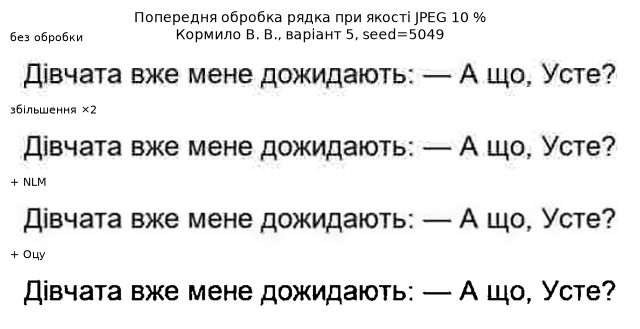

In [6]:
def preprocess(img, steps=()):
    out = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if "upscale" in steps:
        out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    if "nlm" in steps:
        out = cv2.fastNlMeansDenoising(out, None, h=15, templateWindowSize=7, searchWindowSize=21)
    if "median" in steps:
        out = cv2.medianBlur(out, 3)
    if "otsu" in steps:
        out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    if "adaptive" in steps:
        out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 15)
    return out


PREP = {"raw": (), "prep": ("upscale", "nlm", "otsu")}

demo = imread_gray(f"data/synth/000_{FACTOR}_10.png")
fig, axes = plt.subplots(4, 1, figsize=(8, 3.6))
for ax, (name, steps) in zip(axes, [("без обробки", ()), ("збільшення ×2", ("upscale",)),
                                     ("+ NLM", ("upscale", "nlm")), ("+ Оцу", ("upscale", "nlm", "otsu"))]):
    ax.imshow(preprocess(demo, steps), cmap="gray", vmin=0, vmax=255)
    ax.set_title(name, fontsize=8, loc="left")
    ax.axis("off")
fig.suptitle(f"Попередня обробка рядка при якості JPEG 10 %\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
savefig(fig, "fig0c_preprocessing")

## 6. Інструменти розпізнавання

* **Tesseract**: `--oem 1` (LSTM), `--psm 7` для рядка, `--psm 6` для картки/сторінки, мова `ukr+eng`.
  Впевненість — середнє `conf` слів / 100.
* **VLM Qwen2.5-VL 7B** (Ollama, Q4_K_M), `temperature = 0`, `seed = SEED`. Модель не повертає
  впевненості, тому як її замінник використано **середню ймовірність токенів відповіді**
  `exp(mean(logprob))`. Це не ймовірність правильності, а лише міра «невпевненості» декодера;
  її придатність перевіряється так само, як для Tesseract (Спірмен, крива ризик-покриття).

In [7]:
def ocr_tesseract(img, lang=TESS_LANG, psm=7):
    t0 = time.perf_counter()
    d = pytesseract.image_to_data(img, lang=lang, config=f"--oem 1 --psm {psm}",
                                  output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(d["text"], d["conf"]) if w.strip() and float(c) >= 0]
    text = " ".join(w for w, _ in words)
    conf = np.mean([c for _, c in words]) / 100 if words else 0.0
    return text, float(conf), time.perf_counter() - t0


PROMPT_BASE = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. "
               "Нічого не виправляй, не перекладай і не додавай пояснень.")
PROMPT_HIST = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. Текст написаний "
               "староукраїнським правописом XVII століття: зберігай кожну літеру точно так, як "
               "вона написана, зокрема ѣ, ъ, ы, ѳ, ѵ, є, і. Не замінюй їх сучасними літерами, "
               "нічого не виправляй, не перекладай і не додавай пояснень.")


def png_bytes(img):
    return cv2.imencode(".png", img)[1].tobytes()


VLM_OPTIONS = {"temperature": 0, "seed": SEED, "num_ctx": 3072}
VLM_CACHE_PATH = "results/vlm_cache.jsonl"
VLM_CACHE = {}
if os.path.exists(VLM_CACHE_PATH):
    with open(VLM_CACHE_PATH, encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            VLM_CACHE[rec["key"]] = rec


def ocr_vlm(img, prompt=PROMPT_BASE, max_tokens=256, retries=3):
    """Розпізнавання VLM. Кожна відповідь одразу дописується в results/vlm_cache.jsonl (ключ —
    хеш зображення, промпту і ліміту токенів): перерваний прогін продовжується з місця зупинки,
    а однакові запити (напр. «без обробки» в основному прогоні і в абляції) не повторюються.
    Час `sec` — виміряний під час першого (фактичного) запиту."""
    data = png_bytes(img)
    key = hashlib.sha1(data + prompt.encode() + str(max_tokens).encode()).hexdigest()
    if key in VLM_CACHE and not FORCE:
        c = VLM_CACHE[key]
        return c["text"], c["conf"], c["sec"]
    for attempt in range(retries):
        t0 = time.perf_counter()
        try:
            r = ollama.chat(model=VLM_MODEL, logprobs=True, options={**VLM_OPTIONS, "num_predict": max_tokens},
                            messages=[{"role": "user", "content": prompt, "images": [data]}])
            break
        except ollama.ResponseError as e:   # разові збої llama-server (CUDA) — повторюємо запит
            print("  повтор VLM:", str(e)[:80], flush=True)
            time.sleep(5)
    else:
        raise RuntimeError("VLM недоступна")
    sec = time.perf_counter() - t0
    text = r.message.content.strip()
    text = re.sub(r"^```[a-z]*\s*|\s*```$", "", text).strip()   # прибираємо Markdown-огорожу
    lps = [t.logprob for t in (r.logprobs or [])]
    conf = float(np.exp(np.mean(lps))) if lps else 0.0
    rec = {"key": key, "text": text, "conf": conf, "sec": sec, "tokens_in": r.prompt_eval_count,
           "tokens_out": r.eval_count}
    VLM_CACHE[key] = rec
    with open(VLM_CACHE_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return text, conf, sec


ENGINES = {"Tesseract": lambda im: ocr_tesseract(im, psm=7),
           "VLM": lambda im: ocr_vlm(im, max_tokens=128)}

# прогрів (поза кешем): модель завантажується в пам'ять, щоб час першого запиту не включав завантаження
for _attempt in range(3):
    try:
        ollama.chat(model=VLM_MODEL, options={**VLM_OPTIONS, "num_predict": 4},
                    messages=[{"role": "user", "content": "Прочитай текст.",
                               "images": [png_bytes(render_line("Прогрів моделі", FONTS[0]))]}])
        break
    except ollama.ResponseError as e:
        print("  повтор прогріву:", str(e)[:80])
        time.sleep(5)
# Примітка: на ПОРОЖНЬОМУ білому зображенні 64×256 модель «прочитала» «Всім привіт! Як вам досить? ...» —
# приклад галюцинації VLM; для прогріву тому використовується рядок з текстом.
print("VLM готова")


def run_cached(name, make_rows):
    """Результати розпізнавання кешуються в results/<name>.csv, щоб ноутбук перезапускався швидко."""
    path = f"results/{name}.csv"
    if os.path.exists(path) and not FORCE:
        return pd.read_csv(path, keep_default_na=False)
    df = pd.DataFrame(make_rows())
    df.to_csv(path, index=False, lineterminator="\n")
    return pd.read_csv(path, keep_default_na=False)


def progress(k, n, t0, every=50):
    if k % every == 0 or k == n:
        print(f"  {k}/{n}, {time.perf_counter() - t0:.0f} с", flush=True)

VLM готова


## 7. Нормалізація тексту та метрики

Правила нормалізації (однакові для всіх інструментів):
1. Unicode NFC (й, ї як один символ).
2. Усі апострофи (’ ʼ ‘ ` ´) → `'`; «ялинки», „лапки“ та “лапки” → `"`.
3. Будь-які послідовності пробілів і переведень рядка → один пробіл; пробіли по краях прибираються.
4. Регістр і пунктуацію **не** ігноруємо: у варіанті досліджується точне відтворення
   правопису, тож будь-яка зміна символу є помилкою. Історичні графеми **не** замінюються
   сучасними (окремо рахується CER після «осучаснювальної» нормалізації — розділ 13).

CER = (S + D + I) / N (символи), WER — те саме для слів. Усереднення **макро**: середнє CER
окремих зразків (кожен рядок/картка має однакову вагу); мікро-CER наводиться окремо в таблиці.

In [8]:
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"
QUOTES = "\u00ab\u00bb\u201e\u201c\u201d"


def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    for q in QUOTES:
        s = s.replace(q, '"')
    return re.sub(r"\s+", " ", s).strip()


def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))


def wer(gt, pred):
    gt, pred = normalize(gt).split(), normalize(pred).split()
    return Levenshtein.distance(gt, pred) / max(1, len(gt))


def add_metrics(df):
    df = df.copy()
    df["pred"] = df["pred"].astype(str)
    df["cer"] = [cer(g, p) for g, p in zip(df["gt"], df.pred)]
    df["wer"] = [wer(g, p) for g, p in zip(df["gt"], df.pred)]
    df["len_ratio"] = [len(normalize(p)) / max(1, len(normalize(g))) for g, p in zip(df["gt"], df.pred)]
    df["dist"] = [Levenshtein.distance(normalize(g), normalize(p)) for g, p in zip(df["gt"], df.pred)]
    df["n"] = [len(normalize(g)) for g in df["gt"]]
    return df


def boot_ci(x, n_boot=2000, alpha=0.05):
    """Бутстреп-інтервал для середнього значення метрики."""
    x = np.asarray(x, float)
    means = rng_boot.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])


def paired_boot(a, b, n_boot=2000, alpha=0.05):
    """Бутстреп парної різниці середніх (a - b) на тих самих зразках."""
    d = np.asarray(a, float) - np.asarray(b, float)
    idx = rng_boot.integers(0, len(d), size=(n_boot, len(d)))
    means = d[idx].mean(axis=1)
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return d.mean(), lo, hi, (means <= 0).mean()


print(cer("інженерія даних", "інженерія даиих"), wer("інженерія даних", "інженерія даиих"))

0.06666666666666667 0.5


## 8. Розпізнавання синтетичного набору

240 зображень × 2 інструменти × 2 варіанти обробки = 960 запусків. Час включає попередню обробку.

In [9]:
def synth_rows(frame=None):
    frame = ds if frame is None else frame
    rows, t0 = [], time.perf_counter()
    for k, r in enumerate(frame.itertuples(), 1):
        img = imread_gray(r.path)
        for prep_name, steps in PREP.items():
            tp = time.perf_counter()
            pim = preprocess(img, steps)
            tp = time.perf_counter() - tp
            for eng, fn in ENGINES.items():
                text, conf, sec = fn(pim)
                rows.append({"id": r.id, "level": r.level, "engine": eng, "prep": prep_name,
                             "gt": r.gt, "pred": text, "conf": conf, "sec": sec + tp})
        progress(k, len(frame), t0, every=10)
    return rows


res = add_metrics(run_cached("synth", synth_rows))
res["config"] = res.engine + " / " + res.prep

summary = (res.groupby(["engine", "prep", "level"])
           .agg(CER_mean=("cer", "mean"), CER_median=("cer", "median"), WER_mean=("wer", "mean"),
                empty=("pred", lambda s: (s.str.strip() == "").mean()), ms=("sec", "mean")))
summary["ms"] *= 1000
print(summary.round(3).to_string())

                      CER_mean  CER_median  WER_mean  empty         ms
engine    prep level                                                  
Tesseract prep 5         0.016         0.0     0.043    0.0    335.110
               10        0.011         0.0     0.028    0.0    339.393
               20        0.013         0.0     0.035    0.0    329.248
               30        0.011         0.0     0.032    0.0    331.850
               50        0.011         0.0     0.030    0.0    337.985
               100       0.011         0.0     0.033    0.0    349.129
          raw  5         0.016         0.0     0.036    0.0    191.408
               10        0.011         0.0     0.033    0.0    188.408
               20        0.009         0.0     0.022    0.0    189.389
               30        0.010         0.0     0.028    0.0    187.768
               50        0.012         0.0     0.034    0.0    196.423
               100       0.010         0.0     0.028    0.0    190.629
VLM   

In [10]:
tab = res.pivot_table(index="config", columns="level", values="cer", aggfunc="mean")[LEVELS] * 100
print("Середній CER, %, залежно від якості JPEG")
print(tab.round(1).to_string())
micro = res.groupby(["config", "level"]).apply(lambda g: g.dist.sum() / g.n.sum()).unstack()[LEVELS] * 100
print("\nМікро-CER, %")
print(micro.round(1).to_string())
print("\nСередній WER, %")
print((res.pivot_table(index="config", columns="level", values="wer", aggfunc="mean")[LEVELS] * 100).round(1).to_string())

Середній CER, %, залежно від якості JPEG
level             100  50   30   20   10   5  
config                                        
Tesseract / prep  1.1  1.1  1.1  1.3  1.1  1.6
Tesseract / raw   1.0  1.2  1.0  0.9  1.1  1.6
VLM / prep        0.9  1.0  1.1  0.9  1.5  1.6
VLM / raw         1.0  1.0  1.1  1.2  1.4  2.2

Мікро-CER, %
level             100  50   30   20   10   5  
config                                        
Tesseract / prep  1.3  1.3  1.3  1.5  1.2  2.0
Tesseract / raw   1.2  1.4  1.2  1.2  1.2  1.5
VLM / prep        1.0  1.1  1.2  1.0  1.5  1.6
VLM / raw         1.1  1.1  1.2  1.2  1.4  2.2

Середній WER, %
level             100  50   30   20   10    5  
config                                         
Tesseract / prep  3.3  3.0  3.2  3.5  2.8   4.3
Tesseract / raw   2.8  3.4  2.8  2.2  3.3   3.6
VLM / prep        3.7  5.4  5.8  3.6  8.0   7.8
VLM / raw         5.4  5.4  6.4  5.7  7.7  10.5


## 9. Графіки метрик
### 9.1. Крива стійкості до стиснення JPEG

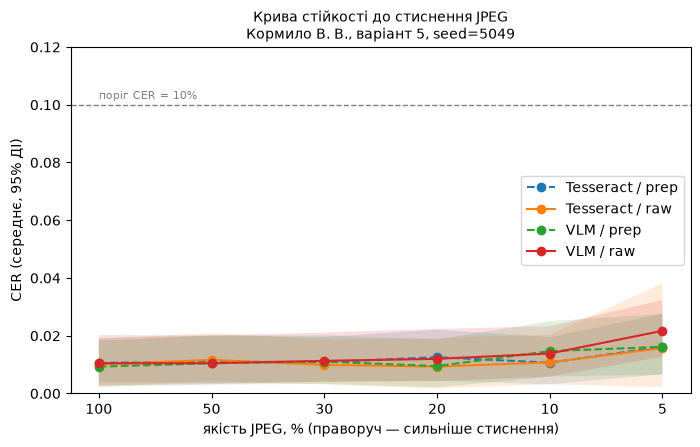

level             100  50   30   20   10   5  
config                                        
Tesseract / prep  1.1  1.1  1.1  1.3  1.1  1.6
Tesseract / raw   1.0  1.2  1.0  0.9  1.1  1.6
VLM / prep        0.9  1.0  1.1  0.9  1.5  1.6
VLM / raw         1.0  1.0  1.1  1.2  1.4  2.2


In [11]:
XPOS = {lvl: k for k, lvl in enumerate(LEVELS)}
fig, ax = plt.subplots(figsize=(8, 4.5))
ci_table = []
for cfg, g in res.groupby("config"):
    by_lvl = g.groupby("level")["cer"]
    mean = by_lvl.mean()[LEVELS]
    ci = np.array([boot_ci(by_lvl.get_group(l)) for l in LEVELS])
    xs = [XPOS[l] for l in LEVELS]
    ls = "-" if cfg.endswith("raw") else "--"
    ax.plot(xs, mean.values, marker="o", ls=ls, label=cfg)
    ax.fill_between(xs, ci[:, 0], ci[:, 1], alpha=0.15)
    for l, m, (lo, hi) in zip(LEVELS, mean.values, ci):
        ci_table.append({"config": cfg, "level": l, "mean": m, "lo": lo, "hi": hi, "width": hi - lo})
ax.axhline(0.10, ls="--", c="grey", lw=1)
ax.text(0, 0.102, "поріг CER = 10%", color="grey", fontsize=8)
ax.set_ylim(0, 0.12)
ax.set_xticks(range(len(LEVELS)), [str(l) for l in LEVELS])
ax.set_xlabel("якість JPEG, % (праворуч — сильніше стиснення)")
ax.set_ylabel("CER (середнє, 95% ДІ)")
ax.legend()
stamp(ax, "Крива стійкості до стиснення JPEG")
savefig(fig, "fig1_robustness")

ci_table = pd.DataFrame(ci_table)
print(ci_table.pivot(index="config", columns="level", values="mean")[LEVELS].mul(100).round(1).to_string())

**Питання 1.** Рівень, на якому CER уперше перевищує 10 %, і перетин кривих.

In [12]:
for cfg, g in ci_table.groupby("config"):
    g = g.set_index("level").loc[LEVELS]
    over = [l for l in LEVELS if g.loc[l, "mean"] > 0.10]
    print(f"{cfg:20s}: CER > 10% уперше при якості {over[0] if over else '— (не перевищує)'} %")

raw = ci_table[ci_table.config.str.endswith("raw")].pivot(index="level", columns="config", values="mean").loc[LEVELS]
sign = np.sign(raw["Tesseract / raw"] - raw["VLM / raw"])
print("\nЗнак різниці (Tesseract − VLM), raw:", dict(zip(LEVELS, sign.astype(int))))
cross = [(LEVELS[k], LEVELS[k + 1]) for k in range(len(LEVELS) - 1) if sign.iloc[k] != sign.iloc[k + 1]]
print("Перетин кривих між рівнями:", cross if cross else "немає")

Tesseract / prep    : CER > 10% уперше при якості — (не перевищує) %
Tesseract / raw     : CER > 10% уперше при якості — (не перевищує) %
VLM / prep          : CER > 10% уперше при якості — (не перевищує) %
VLM / raw           : CER > 10% уперше при якості — (не перевищує) %

Знак різниці (Tesseract − VLM), raw: {100: -1, 50: 1, 30: -1, 20: -1, 10: -1, 5: -1}
Перетин кривих між рівнями: [(100, 50), (50, 30)]


**Інтерпретація рис. 1 і питання 1.** Осі: якість JPEG (праворуч — сильніше стиснення) і середній
CER 40 рядків з 95 % бутстреп-інтервалом; точка — середнє по рівню. Орієнтири: поріг CER = 10 % і
значення при якості 100 %. Усі чотири конфігурації лежать на плато 0,9–1,2 % від якості 100 % до
10 %; помітне зростання лише при 5 %: Tesseract/raw 1,0 → 1,6 %, VLM/raw 1,0 → 2,2 %.
**Рівня, на якому CER перевищує 10 %, немає для жодного інструмента**: максимум 2,2 % у 4,5 раза
нижчий за поріг. Формально знак різниці T − V змінюється між якістю 100 і 50 % та 50 і 30 %, але
різниці 0,05–0,3 в. п. у кілька разів менші за ширину смуг (1,6–3,6 в. п.), тож це шум, а не
перетин кривих (рис. 1b). Смуги однаково вузькі на плато (1,6–1,8 в. п.); найширша — Tesseract/raw
при 5 % (3,6 в. п.) через один рядок з CER 0,40 (рис. 2). Причина стійкості: висота літер 22–35 px
у кілька разів більша за блок стиснення 8×8 px — артефакти дають «ореоли», але не руйнують
форму літер. Практичний висновок: для тексту такого розміру стиснення JPEG до 10 % безпечне для
обох інструментів, і вибір визначається швидкістю (рис. 4). Перевірка пояснення — додатковий
експеримент з дрібним шрифтом (розділ 13a, рис. 12), де криві справді перетинаються.

### 9.2. Бутстреп парної різниці (питання 3)

 level  diff_T_minus_V      lo     hi  zero_in_CI  share_T_not_worse
   100         -0.0005 -0.0061 0.0063        True             0.5555
    50          0.0012 -0.0064 0.0086        True             0.3925
    30         -0.0014 -0.0082 0.0058        True             0.6565
    20         -0.0027 -0.0081 0.0033        True             0.8420
    10         -0.0031 -0.0099 0.0049        True             0.7825
     5         -0.0060 -0.0193 0.0120        True             0.7815
Рівень з найбільшою різницею між інструментами: 5


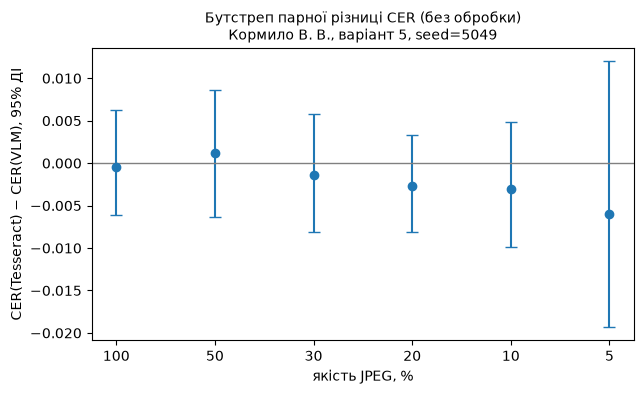

In [13]:
paired = []
for lvl in LEVELS:
    a = res[(res.level == lvl) & (res.config == "Tesseract / raw")].sort_values("id").cer.values
    b = res[(res.level == lvl) & (res.config == "VLM / raw")].sort_values("id").cer.values
    m, lo, hi, p_le0 = paired_boot(a, b)
    paired.append({"level": lvl, "diff_T_minus_V": m, "lo": lo, "hi": hi, "zero_in_CI": lo <= 0 <= hi,
                   "share_T_not_worse": p_le0})
paired = pd.DataFrame(paired)
print(paired.round(4).to_string(index=False))
LVL_MAX = int(paired.loc[paired.diff_T_minus_V.abs().idxmax(), "level"])
print("Рівень з найбільшою різницею між інструментами:", LVL_MAX)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(range(len(LEVELS)), paired.diff_T_minus_V, yerr=[paired.diff_T_minus_V - paired.lo, paired.hi - paired.diff_T_minus_V],
            fmt="o", capsize=4)
ax.axhline(0, c="grey", lw=1)
ax.set_xticks(range(len(LEVELS)), [str(l) for l in LEVELS])
ax.set_xlabel("якість JPEG, %")
ax.set_ylabel("CER(Tesseract) − CER(VLM), 95% ДІ")
stamp(ax, "Бутстреп парної різниці CER (без обробки)")
savefig(fig, "fig1b_paired_bootstrap")

**Питання 3.** Найбільша різниця середніх — при якості 5 %: CER(Tesseract) − CER(VLM) = −0,60 в. п.,
95 % інтервал парної різниці [−1,93; +1,20] в. п. **містить нуль**; Tesseract не гірший за VLM у 78 %
бутстреп-вибірок. Нуль міститься в інтервалах на всіх шести рівнях (рис. 1b), тобто на 40 рядках
великого друкованого шрифту інструменти статистично нерозрізнювані.

### 9.3. Розподіл CER: діаграма розмаху і гістограма (питання 4)

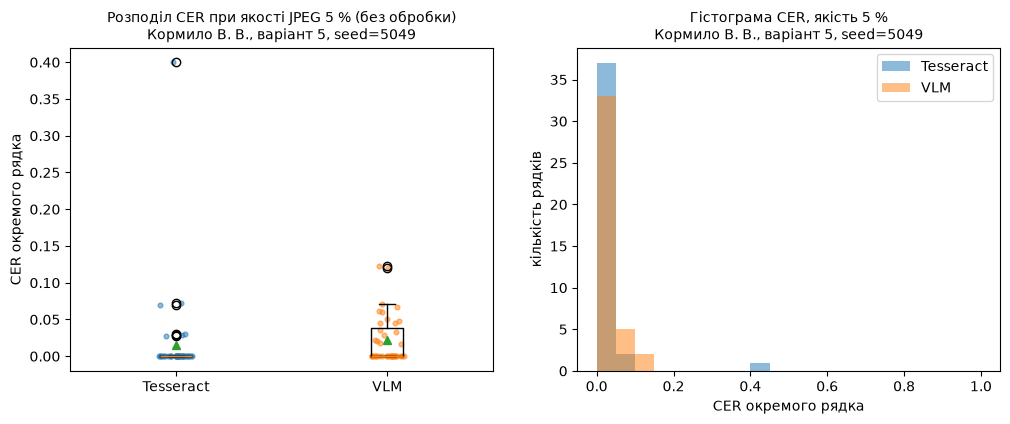

Tesseract  середнє=0.016 медіана=0.000 IQR=[0.000; 0.000] max=0.400 CER>=1: 0% порожніх: 0%
VLM        середнє=0.022 медіана=0.000 IQR=[0.000; 0.038] max=0.123 CER>=1: 0% порожніх: 0%

Повні провали (CER ≥ 1) по всіх рівнях, raw:
немає


In [14]:
LVL_BOX = LVL_MAX
sub = res[(res.level == LVL_BOX) & (res.prep == "raw")]
names = sorted(sub.engine.unique())
groups = [sub[sub.engine == e]["cer"].values for e in names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.boxplot(groups, tick_labels=names, showmeans=True)
for k, g in enumerate(groups, start=1):
    ax.scatter(np.full(len(g), k) + rng_plot.uniform(-0.08, 0.08, len(g)), g, s=12, alpha=0.5)
ax.set_ylabel("CER окремого рядка")
stamp(ax, f"Розподіл CER при якості JPEG {LVL_BOX} % (без обробки)")
ax = axes[1]
bins = np.linspace(0, max(1.0, sub.cer.max()), 21)
for e, g in zip(names, groups):
    ax.hist(g, bins=bins, alpha=0.5, label=e)
ax.set_xlabel("CER окремого рядка")
ax.set_ylabel("кількість рядків")
ax.legend()
stamp(ax, f"Гістограма CER, якість {LVL_BOX} %")
savefig(fig, "fig2_boxplot")

for e, g in zip(names, groups):
    q1, med, q3 = np.quantile(g, [0.25, 0.5, 0.75])
    print(f"{e:10s} середнє={g.mean():.3f} медіана={med:.3f} IQR=[{q1:.3f}; {q3:.3f}] max={g.max():.3f} "
          f"CER>=1: {(g >= 1).mean():.0%} порожніх: {(sub[sub.engine == e].pred.str.strip() == '').mean():.0%}")
fails = res[(res.cer >= 1) & (res.prep == "raw")]
print("\nПовні провали (CER ≥ 1) по всіх рівнях, raw:")
print(fails.groupby(["engine", "level"]).size().to_string() if len(fails) else "немає")

**Інтерпретація рис. 2 і питання 4.** Рівень 5 % — точка найбільшої різниці. Медіани обох
інструментів дорівнюють 0 (більшість рядків розпізнано без жодної помилки), а середні — 1,6 %
(Tesseract) і 2,2 % (VLM): середнє вище медіани через правий хвіст. У Tesseract міжквартильний
розмах [0; 0] — щонайменше 75 % рядків ідеальні, а середнє тягне вгору один викид CER = 0,40:
«Та вона-ж голодна, серце…» → «Ta BoHa- голодна, серце...» — латинські гомогліфи (Т → T, в → B,
н → H) у сильно стиснутому рядку плюс «…» → «...». У VLM розмах [0; 3,8 %], максимум 12,3 %:
помилки дрібніші, але частіші. Гістограма: обидва розподіли мають моду в нулі й довгий хвіст,
тобто не нормальні. **Частка повних провалів (CER = 1) — 0 %** на всіх рівнях для обох
інструментів, тому відкривати такі зображення не довелося; натомість переглянуто викид 0,40.
Висновок «Tesseract кращий на 0,6 в. п.» за середнім некоректний: різницю створює один рядок.

### 9.4. Впевненість проти помилки і крива ризик-покриття (питання 5)

Tesseract  Спірмен ρ = -0.284 (p = 7.6e-06); CER ≤ 2%: покриття 100%, поріг впевненості 0.742
           CER ≤ 1.0%: покриття 100%, поріг впевненості 0.805
           CER ≤ 0.5%: покриття 56%, поріг впевненості 0.9429
           серед 15 найупевненіших: помилкових 0, макс. CER 0.000
VLM        Спірмен ρ = -0.401 (p = 1.2e-10); CER ≤ 2%: покриття 100%, поріг впевненості 0.81
           CER ≤ 1.0%: покриття 94%, поріг впевненості 0.901
           CER ≤ 0.5%: покриття 3%, поріг впевненості 0.9978
           серед 15 найупевненіших: помилкових 3, макс. CER 0.120


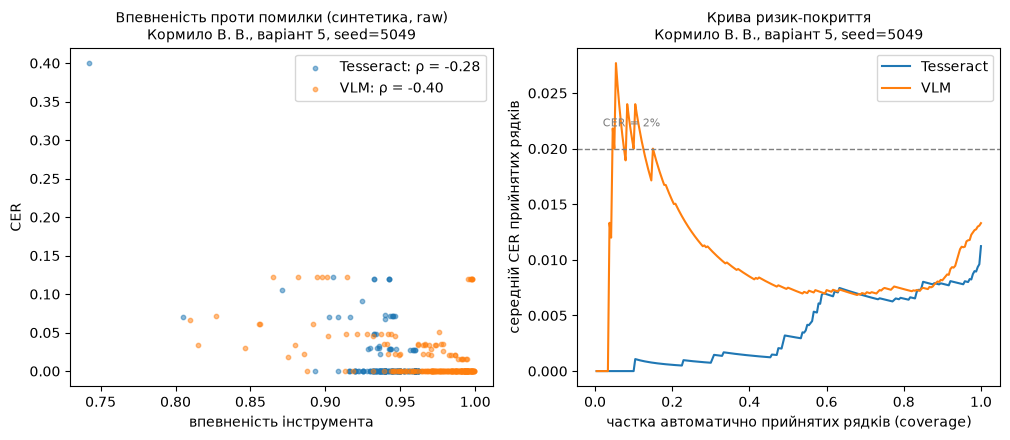

In [15]:
def coverage_at(g, max_cer=0.02):
    """Максимальна частка автоматично прийнятих зразків, для якої середній CER прийнятих ≤ max_cer."""
    g = g.sort_values("conf", ascending=False)
    risk = g.cer.cumsum().values / np.arange(1, len(g) + 1)
    ok = np.where(risk <= max_cer)[0]
    if len(ok) == 0:
        return 0.0, None, risk
    k = ok.max()
    return (k + 1) / len(g), g.conf.values[k], risk


fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for eng, g in res[res.prep == "raw"].groupby("engine"):
    rho, p = spearmanr(g.conf, g.cer)
    axes[0].scatter(g.conf, g.cer, s=10, alpha=0.5, label=f"{eng}: ρ = {rho:.2f}")
    cov, thr, risk = coverage_at(g)
    coverage = np.arange(1, len(g) + 1) / len(g)
    axes[1].plot(coverage, risk, label=eng)
    print(f"{eng:10s} Спірмен ρ = {rho:.3f} (p = {p:.1e}); CER ≤ 2%: покриття {cov:.0%}, "
          f"поріг впевненості {thr if thr is None else round(thr, 3)}")
    for target in (0.01, 0.005):
        c2, t2, _ = coverage_at(g, target)
        print(f"{'':10s} CER ≤ {target:.1%}: покриття {c2:.0%}, поріг впевненості {t2 if t2 is None else round(t2, 4)}")
    top = g.sort_values("conf", ascending=False).head(15)
    print(f"{'':10s} серед 15 найупевненіших: помилкових {(top.cer > 0).sum()}, макс. CER {top.cer.max():.3f}")
axes[0].set_xlabel("впевненість інструмента")
axes[0].set_ylabel("CER")
axes[0].legend()
stamp(axes[0], "Впевненість проти помилки (синтетика, raw)")
axes[1].axhline(0.02, ls="--", c="grey", lw=1)
axes[1].text(0.02, 0.022, "CER = 2%", color="grey", fontsize=8)
axes[1].set_xlabel("частка автоматично прийнятих рядків (coverage)")
axes[1].set_ylabel("середній CER прийнятих рядків")
axes[1].legend()
stamp(axes[1], "Крива ризик-покриття")
savefig(fig, "fig3_confidence")

**Інтерпретація рис. 3 і питання 5.** Коефіцієнт Спірмена: Tesseract ρ = −0,28, VLM ρ = −0,40
(p < 10⁻⁵) — зв'язок від'ємний, але слабкий/помірний. Поріг «CER ≤ 2 %» на синтетиці не
інформативний: середній CER усього набору ≈ 1 %, тому обидва інструменти обробляють **100 %**
рядків автоматично (поріг впевненості 0,742 для Tesseract, 0,81 для VLM). Для суворіших цілей:
CER ≤ 1 % — Tesseract 100 % (поріг 0,805), VLM 94 % (поріг 0,901); CER ≤ 0,5 % — Tesseract 56 %
(поріг 0,943), VLM лише 3 % (поріг 0,998). Крива VLM на малому покритті піднімається до 2,8 %:
серед 15 найупевненіших відповідей 3 помилкові з CER 12 % — рядок «Та вона-ж голодна, серце…»,
де VLM з впевненістю 0,998 пише «...» замість «…». Це систематична типографська розбіжність, яку
модель не вважає помилкою: порогом її не відфільтрувати, але правило постобробки її прибирає
(розділ 15). На картках Perestoroha (рис. 7) картина інша: ρ(VLM) = −0,66, і 47 % карток можна
приймати автоматично з CER ≤ 10 % (поріг 0,79), а впевненість Tesseract (ρ = −0,08) непридатна.
Нагадування: «впевненість» VLM — середня ймовірність токенів, а не ймовірність правильності.

### 9.5. Компроміс якість-швидкість (питання 6)

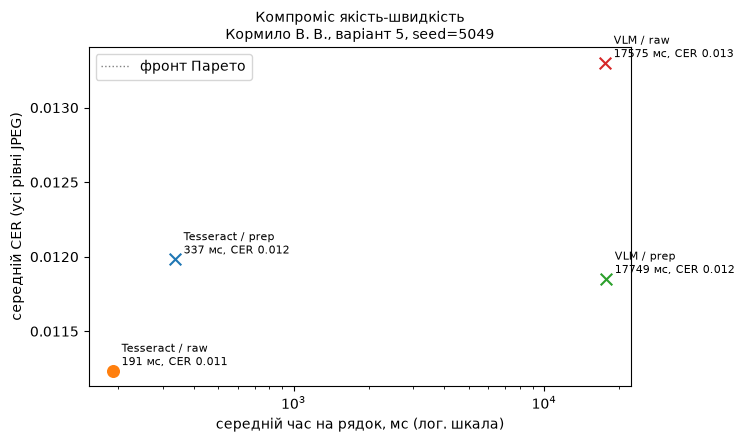

          config    cer         ms                      dominated_by
Tesseract / prep 0.0120   337.1192                   Tesseract / raw
 Tesseract / raw 0.0112   190.6706                                  
      VLM / prep 0.0119 17749.4210                   Tesseract / raw
       VLM / raw 0.0133 17574.7387 Tesseract / prep, Tesseract / raw


In [16]:
agg = res.groupby("config").agg(cer=("cer", "mean"), ms=("sec", "mean")).reset_index()
agg["ms"] *= 1000
agg["dominated_by"] = [", ".join(o.config for o in agg.itertuples()
                                 if o.config != r.config and o.cer <= r.cer and o.ms <= r.ms
                                 and (o.cer < r.cer or o.ms < r.ms)) for r in agg.itertuples()]
fig, ax = plt.subplots(figsize=(7, 4.4))
for r in agg.itertuples():
    ax.scatter(r.ms, r.cer, s=70, marker="o" if not r.dominated_by else "x")
    ax.annotate(f"{r.config}\n{r.ms:.0f} мс, CER {r.cer:.3f}", (r.ms, r.cer), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
front = agg[agg.dominated_by == ""].sort_values("ms")
ax.plot(front.ms, front.cer, c="grey", lw=1, ls=":", label="фронт Парето")
ax.set_xscale("log")
ax.set_xlabel("середній час на рядок, мс (лог. шкала)")
ax.set_ylabel("середній CER (усі рівні JPEG)")
ax.legend()
stamp(ax, "Компроміс якість-швидкість")
savefig(fig, "fig4_pareto")
print(agg.round(4).to_string(index=False))

**Інтерпретація рис. 4 і питання 6.** Осі: середній час на рядок (лог. шкала) і середній CER по
всіх рівнях. Недомінована лише **Tesseract/raw** (191 мс, CER 1,12 %). Її домінують: Tesseract/prep
(337 мс, 1,20 %), VLM/prep (17,7 с, 1,19 %), VLM/raw (17,6 с, 1,33 %). VLM у ≈ 92 рази повільніша без
виграшу в якості; різниці CER 0,1–0,2 в. п. — у межах похибки. **10 000 сторінок за ніч** (8 год =
28 800 с ⇒ ≤ 2,9 с на сторінку): для друкованих документів — Tesseract/raw (≈ 0,4 с на картку ⇒
≈ 1,1 год на 10 000). Для рукописних карток Tesseract непридатний (CER 80 %, розділ 10), а VLM на
цьому ПК (GTX 1660 Ti 6 ГБ, 41 % моделі на CPU) потребує ≈ 26 с на картку ⇒ ≈ 72 год, у 9 разів
більше за бюджет. Тоді рішення — VLM на GPU, де модель повністю вміщується у відеопам'ять, або
кілька GPU, плюс маршрутизація за впевненістю (рис. 7).

### 9.6. Абляційний експеримент (питання 7)

Tesseract — усі 6 конфігурацій на всіх рівнях (запуски дешеві); VLM — 4 конфігурації на рівні
`ABL_LEVEL`. Кроки додаються послідовно, останні два рядки — альтернативи окремим крокам.

Tesseract: середній CER, % за кроками обробки і рівнями JPEG
level                  100  50   30   20   10   5  
step                                               
без обробки            1.0  1.2  1.0  0.9  1.1  1.6
+ збільшення ×2        0.9  0.9  1.0  0.9  1.0  1.2
+ NLM-фільтр           0.9  1.0  1.2  0.9  1.0  1.5
+ бінаризація Оцу      1.1  1.1  1.1  1.3  1.1  1.6
адаптивна замість Оцу  1.2  0.9  1.4  1.1  1.7  1.5
медіанний замість NLM  1.1  1.2  1.0  1.0  1.0  1.2


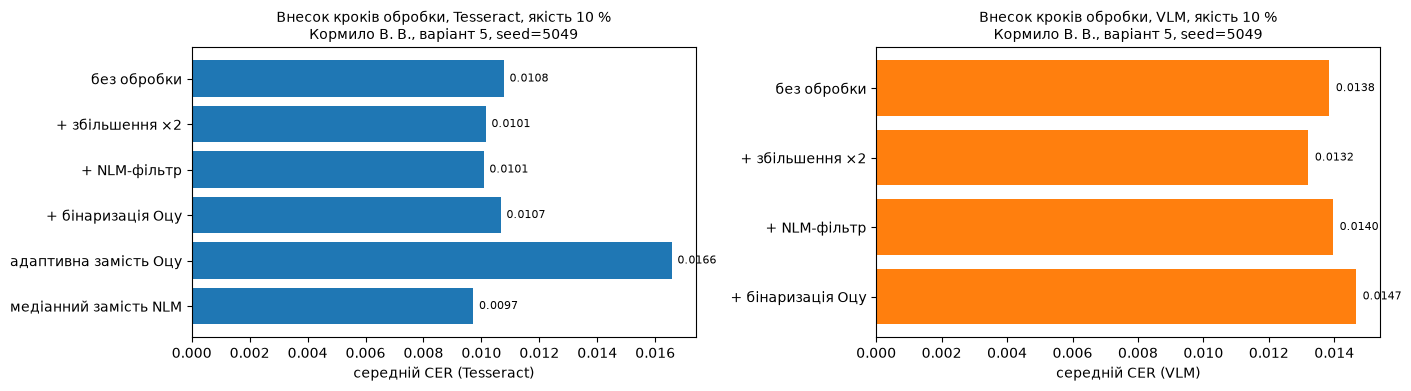

engine                 Tesseract     VLM
step                                    
без обробки               0.0108  0.0138
+ збільшення ×2           0.0101  0.0132
+ NLM-фільтр              0.0101  0.0140
+ бінаризація Оцу         0.0107  0.0147
адаптивна замість Оцу     0.0166     NaN
медіанний замість NLM     0.0097     NaN


In [17]:
ABL_LEVEL = 10
ablation = {"без обробки": (),
            "+ збільшення ×2": ("upscale",),
            "+ NLM-фільтр": ("upscale", "nlm"),
            "+ бінаризація Оцу": ("upscale", "nlm", "otsu"),
            "адаптивна замість Оцу": ("upscale", "nlm", "adaptive"),
            "медіанний замість NLM": ("upscale", "median", "otsu")}
ABL_VLM = list(ablation)[:4]


def ablation_rows():
    rows, t0 = [], time.perf_counter()
    for k, r in enumerate(ds.itertuples(), 1):
        img = imread_gray(r.path)
        for name, steps in ablation.items():
            pim = preprocess(img, steps)
            text, conf, sec = ocr_tesseract(pim)
            rows.append({"engine": "Tesseract", "level": r.level, "id": r.id, "step": name, "gt": r.gt, "pred": text})
            if r.level == ABL_LEVEL and name in ABL_VLM:
                text, conf, sec = ocr_vlm(pim, max_tokens=128)
                rows.append({"engine": "VLM", "level": r.level, "id": r.id, "step": name, "gt": r.gt, "pred": text})
        progress(k, len(ds), t0, every=20)
    return rows


abl_all = add_metrics(run_cached("ablation", ablation_rows))
abl_tab = abl_all[abl_all.engine == "Tesseract"].pivot_table(index="step", columns="level", values="cer", sort=False)[LEVELS]
print("Tesseract: середній CER, % за кроками обробки і рівнями JPEG")
print((abl_tab * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), constrained_layout=True)
for ax, eng in zip(axes, ["Tesseract", "VLM"]):
    a = abl_all[(abl_all.engine == eng) & (abl_all.level == ABL_LEVEL)].groupby("step", sort=False)["cer"].mean()
    ax.barh(a.index[::-1], a.values[::-1], color="C0" if eng == "Tesseract" else "C1")
    for y, v in enumerate(a.values[::-1]):
        ax.text(v + 0.0002, y, f"{v:.4f}", va="center", fontsize=8)
    ax.set_xlabel(f"середній CER ({eng})")
    stamp(ax, f"Внесок кроків обробки, {eng}, якість {ABL_LEVEL} %")
savefig(fig, "fig5_ablation")
print(abl_all[abl_all.level == ABL_LEVEL].pivot_table(index="step", columns="engine", values="cer", sort=False).round(4).to_string())

**Інтерпретація рис. 5 і питання 7** (якість 10 %). Tesseract: без обробки 1,08 %; збільшення ×2 —
1,01 % (найбільший приріст серед послідовних кроків, −0,07 в. п.); NLM — без змін (1,01 %); Оцу
повертає до 1,07 %; **адаптивна бінаризація погіршує до 1,66 %** (+0,6 в. п., найгірший крок);
медіанний фільтр замість NLM дає найкраще значення 0,97 %. VLM: 1,38 → 1,32 % (збільшення) →
1,40 % (NLM) → **1,47 % (Оцу)**: бінаризація погіршує. Порівняння з Г2: прогноз «зниження на
третину» спростовано — ефект ≤ 10 %, бо при великому шрифті артефакти майже не шкодять і
виправляти нічого; прогнози про шкоду адаптивної бінаризації та бінаризації для VLM підтвердились.
Механізм: адаптивний поріг з вікном 31 px на білому тлі перетворює «ореоли» JPEG на плями й розриви
штрихів; VLM навчена на природних зображеннях і використовує градації сірого, які бінаризація
прибирає. Надійність: різниці 0,05–0,1 в. п. відповідають ≈ 1 символу на 40 рядків і лежать у межах
похибки; надійний лише висновок про адаптивну бінаризацію. Таблиця над рисунком показує, що на
інших рівнях якості картина та сама.

### 9.7. Аналіз помилок: найчастіші заміни символів (питання 8)

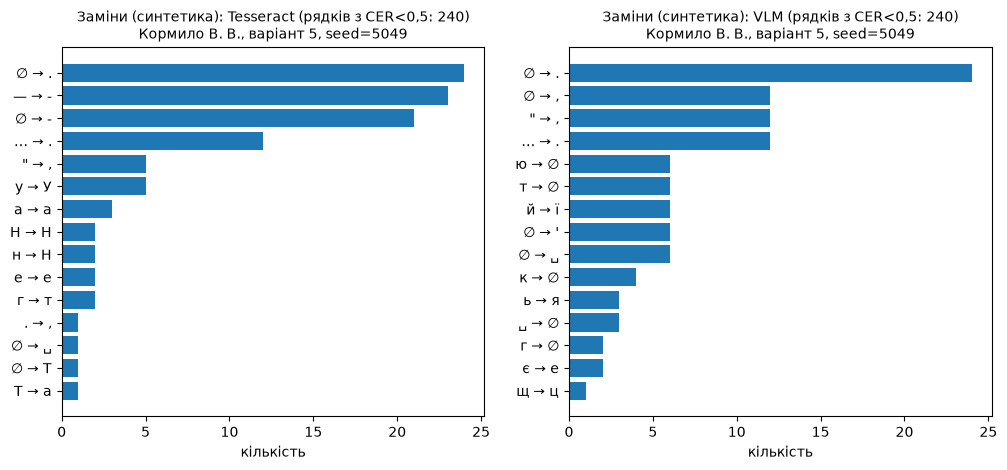

Tesseract {'∅ → .': 24, '— → -': 23, '∅ → -': 21, '… → .': 12, '" → ,': 5, 'у → У': 5, 'а → a': 3, 'Н → H': 2}
VLM {'∅ → .': 24, '∅ → ,': 12, '" → ,': 12, '… → .': 12, 'ю → ∅': 6, 'т → ∅': 6, 'й → ї': 6, "∅ → '": 6}


In [18]:
def sym(c):
    return "␣" if c == " " else c


def confusions(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    pairs = []
    for op in Levenshtein.editops(gt, pred):
        if op.tag == "replace":
            pairs.append(f"{sym(gt[op.src_pos])} → {sym(pred[op.dest_pos])}")
        elif op.tag == "delete":
            pairs.append(f"{sym(gt[op.src_pos])} → ∅")
        else:
            pairs.append(f"∅ → {sym(pred[op.dest_pos])}")
    return pairs


def plot_confusions(frame, title, fname, top_n=15):
    engines = sorted(frame.engine.unique())
    fig, axes = plt.subplots(1, len(engines), figsize=(6 * len(engines), 4.8))
    axes = np.atleast_1d(axes)
    tops = {}
    for ax, eng in zip(axes, engines):
        part = frame[(frame.engine == eng) & (frame.cer < 0.5)]
        c = Counter()
        for r in part.itertuples():
            c.update(confusions(r.gt, r.pred))
        top = pd.Series(dict(c.most_common(top_n)))
        tops[eng] = top
        if len(top):
            ax.barh(top.index[::-1], top.values[::-1])
        else:
            ax.text(0.5, 0.5, "немає частково розпізнаних зразків\n(усі CER ≥ 0,5): заміни не інформативні",
                    ha="center", va="center", transform=ax.transAxes, fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel("кількість")
        stamp(ax, f"{title}: {eng} (рядків з CER<0,5: {len(part)})")
    savefig(fig, fname)
    return tops


tops_synth = plot_confusions(res[res.prep == "raw"], "Заміни (синтетика)", "fig6_confusions")
for eng, top in tops_synth.items():
    print(eng, top.head(8).to_dict())

**Інтерпретація рис. 6.** Tesseract: ∅ → «.» (24), «—» → «-» (23), ∅ → «-» (21), «…» → «.» (12):
три крапки «…» розпізнаються як «...» (1 заміна + 2 вставлення), тире «—» — як «-» або «--»;
далі нижні лапки „ → «,» (5) і гомогліфи а → a (3), Н → H (2). VLM: ті самі «...» (∅ → «.» 24,
«…» → «.» 12), лапки „“ передаються як «,,"» (∅ → «,» і «"» → «,» по 12), а також й → ї, ю → ∅.
Отже, більшість помилок на синтетиці типографські, а не помилки розпізнавання літер, — саме вони
пояснюють плато ≈ 1 % на рис. 1 і «впевнені помилки» VLM на рис. 3. Правила постобробки для п'яти
найчастіших помилок і їх ефект — розділ 15.

## 10. Розпізнавання відкритого набору Perestoroha

Tesseract у режимі `--psm 6` (блок тексту) без обробки і з адаптивною бінаризацією; VLM з двома
інструкціями: базовою (`base`) і з вимогою зберегти дореформений правопис (`hist`).

In [19]:
OPEN_CFG = {
    ("Tesseract", "raw"): lambda p: ocr_tesseract(imread_gray(p), psm=6),
    ("Tesseract", "adaptive"): lambda p: ocr_tesseract(preprocess(imread_gray(p), ("adaptive",)), psm=6),
    ("VLM", "base"): lambda p: ocr_vlm(imread_color(p), PROMPT_BASE, 512),
    ("VLM", "hist"): lambda p: ocr_vlm(imread_color(p), PROMPT_HIST, 512),
}


def open_rows_fn():
    rows, t0 = [], time.perf_counter()
    for k, r in enumerate(ods.itertuples(), 1):
        for (eng, prep_name), fn in OPEN_CFG.items():
            text, conf, sec = fn(r.path)
            rows.append({"k": r.k, "id": r.id, "engine": eng, "prep": prep_name, "gt": r.gt,
                         "pred": text, "conf": conf, "sec": sec})
        progress(k, len(ods), t0, every=10)
    return rows


ores = add_metrics(run_cached("open", open_rows_fn))
ores["config"] = ores.engine + " / " + ores.prep
otab = ores.groupby("config").agg(CER_mean=("cer", "mean"), CER_median=("cer", "median"),
                                  WER_mean=("wer", "mean"), len_ratio=("len_ratio", "median"),
                                  fails=("cer", lambda s: (s >= 1).mean()), s=("sec", "mean"))
otab["CER_micro"] = ores.groupby("config").apply(lambda g: g.dist.sum() / g.n.sum())
otab[["CI_lo", "CI_hi"]] = [boot_ci(g.cer) for _, g in ores.groupby("config")]
print(otab.round(3).to_string())

m, lo, hi, _ = paired_boot(ores[ores.config == "Tesseract / raw"].sort_values("k").cer,
                           ores[ores.config == "VLM / base"].sort_values("k").cer)
print(f"\nПарна різниця CER Tesseract/raw − VLM/base: {m:.3f} [{lo:.3f}; {hi:.3f}]")

                      CER_mean  CER_median  WER_mean  len_ratio  fails       s  CER_micro  CI_lo  CI_hi
config                                                                                                 
Tesseract / adaptive     0.833       0.837     1.011      0.466   0.01   0.289      0.840  0.821  0.845
Tesseract / raw          0.801       0.807     1.032      0.589   0.00   0.392      0.809  0.790  0.812
VLM / base               0.118       0.113     0.444      0.997   0.00  26.333      0.116  0.109  0.126
VLM / hist               0.111       0.107     0.428      1.000   0.00  11.489      0.109  0.104  0.118

Парна різниця CER Tesseract/raw − VLM/base: 0.684 [0.670; 0.697]


Tesseract: ρ = -0.075; CER ≤ 10%: покриття 0%, поріг None
VLM: ρ = -0.659; CER ≤ 10%: покриття 47%, поріг 0.7897770354176802


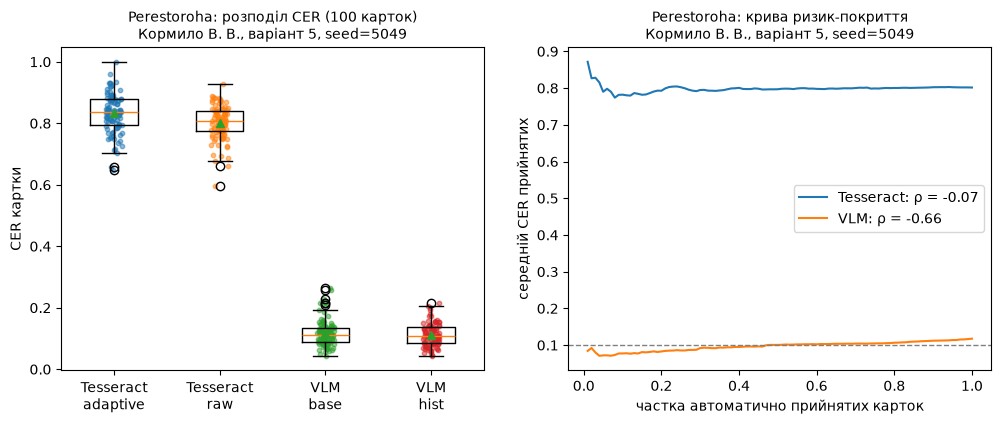

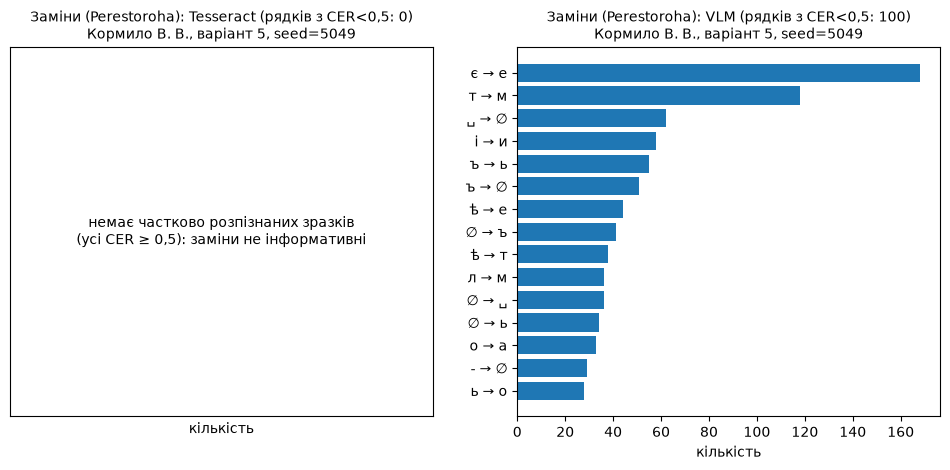

Tesseract {}
VLM {'є → е': 168, 'т → м': 118, '␣ → ∅': 62, 'і → и': 58, 'ъ → ь': 55, 'ъ → ∅': 51, 'ѣ → е': 44, '∅ → ъ': 41, 'ѣ → т': 38, 'л → м': 36}


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cfgs = sorted(ores.config.unique())
gs = [ores[ores.config == c].cer.values for c in cfgs]
axes[0].boxplot(gs, tick_labels=[c.replace(" / ", "\n") for c in cfgs], showmeans=True)
for k, g in enumerate(gs, start=1):
    axes[0].scatter(np.full(len(g), k) + rng_plot.uniform(-0.08, 0.08, len(g)), g, s=10, alpha=0.5)
axes[0].set_ylabel("CER картки")
stamp(axes[0], "Perestoroha: розподіл CER (100 карток)")
for eng, g in ores[ores.prep.isin(["raw", "base"])].groupby("engine"):
    rho, _ = spearmanr(g.conf, g.cer)
    cov, thr, risk = coverage_at(g, 0.10)
    axes[1].plot(np.arange(1, len(g) + 1) / len(g), risk, label=f"{eng}: ρ = {rho:.2f}")
    print(f"{eng}: ρ = {rho:.3f}; CER ≤ 10%: покриття {cov:.0%}, поріг {thr}")
axes[1].axhline(0.10, ls="--", c="grey", lw=1)
axes[1].set_xlabel("частка автоматично прийнятих карток")
axes[1].set_ylabel("середній CER прийнятих")
axes[1].legend()
stamp(axes[1], "Perestoroha: крива ризик-покриття")
savefig(fig, "fig7_open")

tops_open = plot_confusions(ores[ores.prep.isin(["raw", "base"])], "Заміни (Perestoroha)", "fig6b_confusions_open")
for eng, top in tops_open.items():
    print(eng, top.head(10).to_dict())

**Інтерпретація рис. 7 і 6b.** Tesseract: CER 80,1 % [79,0; 81,2], WER 103 % (> 100 % через вставлені
«слова»), довжина результату — 0,59 від еталону: замість скоропису — латинські фрагменти;
адаптивна бінаризація ще гірша (83,3 %). VLM/base: CER 11,8 % [10,9; 12,6], WER 44 %, відношення
довжин 0,997 — довжина збережена, галюцинацій на картках немає, помилки — заміни символів. Парна
різниця Tesseract − VLM = 68,4 в. п. [67,0; 69,7]. Повних провалів (CER ≥ 1) немає (0 % raw, 1 %
adaptive). Порівняння з Г3: Tesseract > 80 % — підтверджено (80,1 %); «частина карток — повний
провал» — спростовано (Tesseract завжди щось повертає); VLM 25–40 % — спростовано: VLM утричі
краща за прогноз. Рис. 6b: у Tesseract немає жодної картки з CER < 0,5, тому заміни не
інформативні; у VLM найчастіші: є → е (168), т → м (118 — скорописне «т» пишеться як «m»),
пропуск пробілу (62), і → и (58), ъ → ь (55), ъ → ∅ (51), ѣ → е (44). Крива ризик-покриття (рис. 7,
праворуч): VLM з ρ = −0,66 дає змогу автоматично приймати 47 % карток з CER ≤ 10 % (поріг 0,79).

## 11. Власні дані

Фото в `my_photos/` (імена латиницею), поруч `.txt` з ручною транскрипцією:
`page01_flat|shadow|angle.jpg` — рукописна сторінка з «Інститутки» в трьох умовах зйомки;
`old01.jpg` — власноруч написаний текст з дореформеними літерами.

Кожне фото: EXIF-орієнтація → відтінки сірого → довша сторона 2000 px. Конфігурації:
`raw`; `warp` — пошук аркуша (Кенні + найбільший чотирикутник) і корекція перспективи;
`warp+adaptive` — плюс адаптивна бінаризація. VLM отримує кольорове зображення (довша сторона
1280 px) без обробки та після корекції перспективи.

In [21]:
def exif_info(path):
    """Дата зйомки та модель камери з EXIF (доказ, що фото зроблене вами)."""
    exif = Image.open(path).getexif()
    tags = {ExifTags.TAGS.get(k, k): v for k, v in exif.items()}
    sub_ifd = exif.get_ifd(0x8769)
    taken = sub_ifd.get(36867) or tags.get("DateTime")
    return taken, tags.get("Model"), tags.get("Make")


def load_photo(path, long_side):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    k = long_side / max(im.size)
    im = im.resize((round(im.width * k), round(im.height * k)), Image.LANCZOS)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)


def order_corners(pts):
    pts = pts.reshape(4, 2).astype(np.float32)
    s, dif = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[s.argmin()], pts[dif.argmin()], pts[s.argmax()], pts[dif.argmax()]])


def find_page(gray, min_area=0.25):
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.dilate(cv2.Canny(blur, 30, 90), np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:5]:
        approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
        if len(approx) == 4 and cv2.contourArea(approx) > min_area * gray.size:
            return order_corners(approx)
    return None


def warp_page(img, corners, width=1400):
    tl, tr, br, bl = corners
    h = int(width * max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
            / max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
    dst = np.float32([[0, 0], [width, 0], [width, h], [0, h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(corners, dst), (width, h))


photos = sorted(f"my_photos/{f}" for f in os.listdir("my_photos")
                if os.path.splitext(f)[1].lower() in (".jpg", ".jpeg"))
print("Фото:", [os.path.basename(p) for p in photos])


def transcription(photo_name):
    """Ручна транскрипція: transcriptions/<ім'я>.txt (або поруч із фото)."""
    stem = os.path.splitext(os.path.basename(photo_name))[0]
    for path in (f"transcriptions/{stem}.txt", f"my_photos/{stem}.txt"):
        if os.path.exists(path):
            with open(path, encoding="utf-8-sig") as f:
                return f.read()
    raise FileNotFoundError(f"немає транскрипції для {photo_name}")


def own_rows_fn():
    rows = []
    for p in photos:
        gt = transcription(p)
        taken, camera, make = exif_info(p)
        big = load_photo(p, 2000)
        gray = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY)
        corners = find_page(gray)
        variants = {"raw": (gray, big)}
        if corners is not None:
            variants["warp"] = (warp_page(gray, corners), warp_page(big, corners))
        base = os.path.basename(p)
        for prep_name, (g_img, c_img) in variants.items():
            imwrite(f"tmp/{os.path.splitext(base)[0]}_{prep_name}.png", g_img)
            for tess_prep, im in [(prep_name, g_img), (prep_name + "+adaptive", preprocess(g_img, ("adaptive",)))]:
                text, conf, sec = ocr_tesseract(im, psm=6)
                rows.append({"file": base, "engine": "Tesseract", "prep": tess_prep, "gt": gt, "pred": text,
                             "conf": conf, "sec": sec, "taken": taken, "camera": camera, "make": make,
                             "page_found": corners is not None})
            vimg = c_img
            k = 1280 / max(vimg.shape[:2])   # ~1570 токенів зображення + до 1024 токенів відповіді < num_ctx 3072
            vimg = cv2.resize(vimg, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
            prompts = {"base": PROMPT_BASE, "hist": PROMPT_HIST} if base.startswith("old") else {"base": PROMPT_BASE}
            for pname, prompt in prompts.items():
                text, conf, sec = ocr_vlm(vimg, prompt, 1024)
                rows.append({"file": base, "engine": "VLM", "prep": f"{prep_name}/{pname}", "gt": gt, "pred": text,
                             "conf": conf, "sec": sec, "taken": taken, "camera": camera, "make": make,
                             "page_found": corners is not None})
        print(" ", base, "готово", flush=True)
    return rows


if photos:
    own = add_metrics(run_cached("own", own_rows_fn))
    print(own[["file", "taken", "camera", "page_found"]].drop_duplicates("file").to_string(index=False))
    print(own.pivot_table(index="file", columns=["engine", "prep"], values="cer").round(3).T.to_string())
else:
    own = pd.DataFrame()
    print("Каталог my_photos порожній — додайте фото і транскрипції")

Фото: ['old01.JPG', 'page01_angle.JPG', 'page01_flat.JPG', 'page01_shadow.JPG']
             file               taken            camera  page_found
        old01.JPG 2026:11:09 20:25:15 iPhone 13 Pro Max        True
 page01_angle.JPG 2026:11:09 20:12:29 iPhone 13 Pro Max       False
  page01_flat.JPG 2026:11:09 20:10:17 iPhone 13 Pro Max        True
page01_shadow.JPG 2026:11:09 20:10:44 iPhone 13 Pro Max       False
file                     old01.JPG  page01_angle.JPG  page01_flat.JPG  page01_shadow.JPG
engine    prep                                                                          
Tesseract raw                0.844             0.866            0.809              0.825
          raw+adaptive       1.170             0.812            0.903              0.828
          warp               1.424               NaN            0.841                NaN
          warp+adaptive      0.960               NaN            1.226                NaN
VLM       raw/base           0.214            

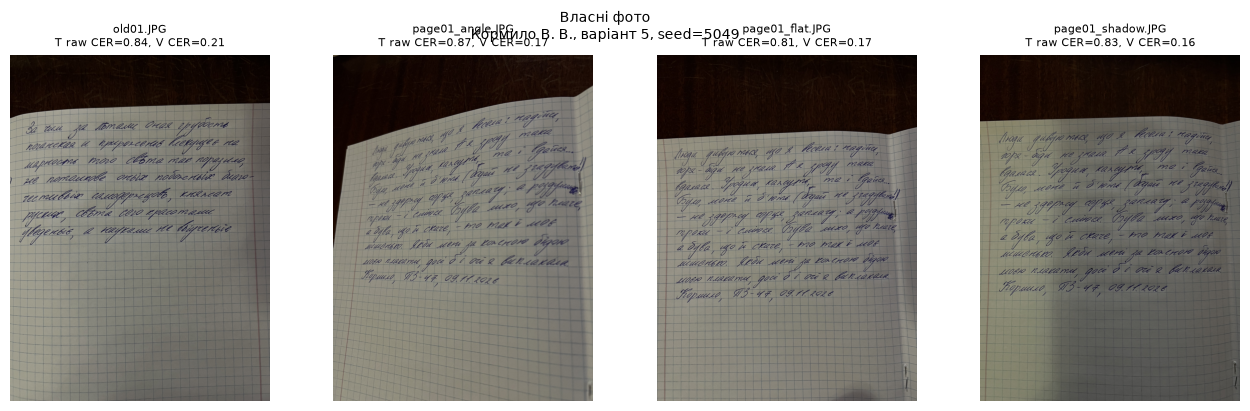

In [22]:
if len(own):
    files = list(dict.fromkeys(own.file))
    fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 4.5))
    for ax, f in zip(np.atleast_1d(axes), files):
        ax.imshow(cv2.cvtColor(load_photo(f"my_photos/{f}", 1000), cv2.COLOR_BGR2RGB))
        g = own[own.file == f]
        ax.set_title(f"{f}\nT raw CER={g[(g.engine == 'Tesseract') & (g.prep == 'raw')].cer.iloc[0]:.2f}, "
                     f"V CER={g[(g.engine == 'VLM') & (g.prep == 'raw/base')].cer.iloc[0]:.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Власні фото\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
    savefig(fig, "fig8_own_photos")

### 11.1. Порівняння трьох груп даних (питання 9)

                        group    engine   n   cer    lo    hi   wer
         синтетика, JPEG 100% Tesseract  40 0.010 0.003 0.019 0.028
         синтетика, JPEG 100%       VLM  40 0.010 0.003 0.019 0.054
         синтетика, усі рівні Tesseract 240 0.011 0.007 0.016 0.030
         синтетика, усі рівні       VLM 240 0.013 0.010 0.017 0.068
     Perestoroha (100 карток) Tesseract 100 0.801 0.790 0.812 1.032
     Perestoroha (100 карток)       VLM 100 0.118 0.110 0.126 0.444
власні: сторінка «Інститутки» Tesseract   3 0.833 0.809 0.866 0.995
власні: сторінка «Інститутки»       VLM   3 0.169 0.159 0.175 0.446
   власні: дореформений текст Tesseract   1 0.844   NaN   NaN 1.182
   власні: дореформений текст       VLM   1 0.214   NaN   NaN 0.576


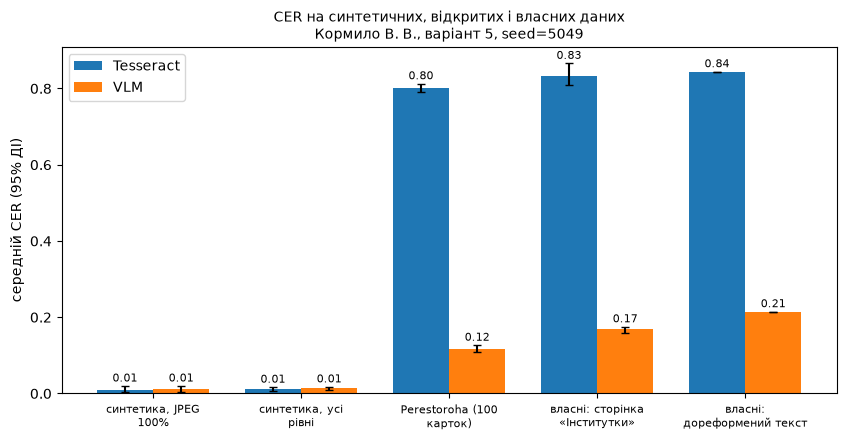

engine             Tesseract    VLM
file                               
page01_angle.JPG       0.866  0.175
page01_flat.JPG        0.809  0.175
page01_shadow.JPG      0.825  0.159


In [23]:
grp = []


def add_group(name, frame, cfg_map):
    for eng, cond in cfg_map.items():
        g = frame[cond(frame) & (frame.engine == eng)]
        if len(g):
            lo, hi = boot_ci(g.cer) if len(g) > 1 else (np.nan, np.nan)
            grp.append({"group": name, "engine": eng, "n": len(g), "cer": g.cer.mean(), "lo": lo, "hi": hi,
                        "wer": g.wer.mean()})


add_group("синтетика, JPEG 100%", res, {e: (lambda f: (f.level == 100) & (f.prep == "raw")) for e in ["Tesseract", "VLM"]})
add_group("синтетика, усі рівні", res, {e: (lambda f: f.prep == "raw") for e in ["Tesseract", "VLM"]})
add_group("Perestoroha (100 карток)", ores, {"Tesseract": lambda f: f.prep == "raw", "VLM": lambda f: f.prep == "base"})
if len(own):
    add_group("власні: сторінка «Інститутки»", own[own.file.str.startswith("page")],
              {"Tesseract": lambda f: f.prep == "raw", "VLM": lambda f: f.prep == "raw/base"})
    add_group("власні: дореформений текст", own[own.file.str.startswith("old")],
              {"Tesseract": lambda f: f.prep == "raw", "VLM": lambda f: f.prep == "raw/base"})
grp = pd.DataFrame(grp)
print(grp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
gnames = list(dict.fromkeys(grp.group))
for j, eng in enumerate(["Tesseract", "VLM"]):
    g = grp[grp.engine == eng].set_index("group").reindex(gnames)
    x = np.arange(len(gnames)) + (j - 0.5) * 0.38
    ax.bar(x, g.cer, width=0.38, label=eng,
           yerr=[(g.cer - g.lo).fillna(0), (g.hi - g.cer).fillna(0)], capsize=3)
    for xi, v, hi in zip(x, g.cer, g.hi):
        if not np.isnan(v):
            ax.text(xi, (v if np.isnan(hi) else max(v, hi)) + 0.012, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(range(len(gnames)), [textwrap.fill(n, 18) for n in gnames], fontsize=8)
ax.set_ylabel("середній CER (95% ДІ)")
ax.legend()
stamp(ax, "CER на синтетичних, відкритих і власних даних")
savefig(fig, "fig9_groups")

if len(own):
    pg = own[own.file.str.startswith("page") & own.prep.isin(["raw", "raw/base"])]
    print(pg.pivot_table(index="file", columns="engine", values="cer").round(3).to_string())

**Інтерпретація рис. 8–9 і питання 9.** Синтетика (JPEG 100 %): 1,0 % в обох інструментів. Власна
рукописна сторінка: Tesseract 83,3 % — **у 83 рази** гірше за синтетику; VLM 16,9 % — **у 17 разів**.
Відносно відкритого набору: Tesseract 1,04× (80,1 → 83,3 %), VLM 1,43× (11,8 → 16,9 %). Порівняння з
Г5: «≥ 10×» — підтверджено для обох; Tesseract > 70 % і VLM 15–30 % — підтверджено. **Найгірша умова
зйомки:** Tesseract — під кутом (86,6 % проти 80,9 % при рівному світлі та 82,5 % з тінню) —
підтверджено; VLM — рівне світло і кут однакові (17,5 %), а тінь найкраща (15,9 %), тож прогноз
«тінь найгірша для VLM» спростовано. Різниця 1,6 в. п. на одному фото на умову статистично
ненадійна: помилки VLM на сторінці визначає почерк («Корнило», «мов/моє»), а не освітлення.
Корекція перспективи допомогла VLM (рівне світло 17,5 → 15,3 %, дореформений текст 21,4 → 14,3 %),
але зашкодила Tesseract (80,9 → 84,1 % і 84,4 → 142 %: після вирівнювання сітка клітинок дає
вставлений «текст»). Пошук аркуша спрацював на 2 з 4 фото: на фото з тінню та під кутом край
сторінки зливається з текстурою столу і сусіднім аркушем.

## 12. Особливість варіанта: чи «осучаснює» VLM правопис

Для кожної позиції еталону з історичною графемою за вирівнюванням Левенштейна визначаємо, що
повернув інструмент: ту саму графему (правильно), її сучасний відповідник (**осучаснення**:
ѣ → і/е/ї, ы → и, ъ → ∅/ь, ѳ → ф, ѵ → і/и/в, э → е), інший символ або нічого.
**CER історичних графем** = частка позицій історичних графем, відтворених неправильно;
так само рахується CER решти (звичайних) символів.

In [24]:
MODERN = {"ѣ": set("іеї"), "ы": set("и"), "ъ": {"", "ь"}, "ѳ": set("ф"), "ѵ": set("іив"), "э": set("е"),
          "Ѣ": set("ІЕЇ"), "Ы": set("И"), "Ъ": {"", "Ь"}, "Ѳ": set("Ф"), "Ѵ": set("ІИВ"), "Э": set("Е")}


def align_chars(gt, pred):
    """Список (символ еталону, символ результату або '' для видалення) для кожної позиції еталону."""
    out = []
    for tag, i1, i2, j1, j2 in Levenshtein.opcodes(gt, pred):
        if tag == "equal" or tag == "replace":
            for k in range(i2 - i1):
                out.append((gt[i1 + k], pred[j1 + k] if j1 + k < j2 else ""))
        elif tag == "delete":
            out.extend((gt[i], "") for i in range(i1, i2))
    return out


def hist_stats(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    st = Counter()
    pairs = Counter()
    for g, p in align_chars(gt, pred):
        if g in HIST:
            st["n_hist"] += 1
            if p == g:
                st["ok_hist"] += 1
            elif p in MODERN[g]:
                st["modern"] += 1
                pairs[f"{g} → {p or '∅'}"] += 1
            else:
                st["other_hist"] += 1
                pairs[f"{g} → {p or '∅'}"] += 1
        elif not g.isspace():
            st["n_reg"] += 1
            st["ok_reg"] += p == g
    st["pred_hist"] = sum(c in HIST for c in pred)
    return st, pairs


def hist_table(frame):
    out, all_pairs = [], {}
    for cfg, g in frame.groupby("config"):
        tot, prs = Counter(), Counter()
        for r in g.itertuples():
            s, p = hist_stats(r.gt, r.pred)
            tot.update(s)
            prs.update(p)
        out.append({"config": cfg, "n_hist": tot["n_hist"],
                    "CER_hist": 1 - tot["ok_hist"] / max(1, tot["n_hist"]),
                    "CER_regular": 1 - tot["ok_reg"] / max(1, tot["n_reg"]),
                    "modernized": tot["modern"] / max(1, tot["n_hist"]),
                    "other_err_hist": tot["other_hist"] / max(1, tot["n_hist"]),
                    "hist_in_pred": tot["pred_hist"]})
        all_pairs[cfg] = prs
    return pd.DataFrame(out), all_pairs


htab, hpairs = hist_table(ores)
print("Perestoroha, 100 карток:")
print(htab.round(3).to_string(index=False))
for cfg, prs in hpairs.items():
    print(cfg, dict(prs.most_common(8)))

Perestoroha, 100 карток:
              config  n_hist  CER_hist  CER_regular  modernized  other_err_hist  hist_in_pred
Tesseract / adaptive     841     1.000        0.902       0.301           0.699             0
     Tesseract / raw     841     1.000        0.875       0.263           0.737             0
          VLM / base     841     0.502        0.093       0.220           0.282           516
          VLM / hist     841     0.436        0.086       0.168           0.269           639
Tesseract / adaptive {'ъ → ∅': 235, 'ы → ∅': 214, 'ѣ → ∅': 172, 'ы → e': 15, 'ъ → e': 10, 'ѣ → o': 7, 'ъ → ь': 7, 'ы → o': 7}
Tesseract / raw {'ъ → ∅': 200, 'ы → ∅': 197, 'ѣ → ∅': 136, 'ъ → e': 15, 'ы → e': 14, 'ы → u': 12, 'ы → и': 11, 'ы → o': 8}
VLM / base {'ъ → ь': 55, 'ъ → ∅': 51, 'ѣ → е': 44, 'ѣ → т': 38, 'ѣ → ь': 25, 'ѣ → ъ': 22, 'ы → и': 19, 'ѣ → б': 18}
VLM / hist {'ъ → ь': 58, 'ъ → ∅': 35, 'ѣ → т': 35, 'ѣ → ъ': 22, 'ѣ → б': 19, 'ѣ → ь': 18, 'ѣ → е': 18, 'ы → и': 16}


**CER після «осучаснювальної» нормалізації.** Якщо і еталон, і результат перевести в сучасні
відповідники (ѣ → і, ы → и, кінцевий ъ → ∅, ѳ → ф, ѵ → і, э → е), різниця CER до і після показує,
яку частку помилок спричинив саме правопис.

In [25]:
MOD_MAP = str.maketrans({"ѣ": "і", "ы": "и", "ѳ": "ф", "ѵ": "і", "э": "е", "Ѣ": "І", "Ы": "И", "Ѳ": "Ф", "Ѵ": "І", "Э": "Е"})


def modernize(s):
    s = normalize(s).translate(MOD_MAP)
    s = re.sub(r"[ъЪ](?=\W|$)", "", s)   # кінцевий єр
    return s.replace("ъ", "'")             # єр всередині слова як роздільник


m, lo, hi, _ = paired_boot(ores[ores.config == "VLM / base"].sort_values("k").cer,
                           ores[ores.config == "VLM / hist"].sort_values("k").cer)
print(f"Парна різниця CER VLM base − hist: {m:.4f} [{lo:.4f}; {hi:.4f}]")
print("Час VLM на картку, с:", ores[ores.engine == "VLM"].groupby("prep").sec.median().round(1).to_dict(),
      "(hist виконувався одразу після base з тим самим зображенням — Ollama повторно використала "
      "закодоване зображення, тому його час не є незалежним заміром)")

ores["cer_mod"] = [cer(modernize(g), modernize(p)) for g, p in zip(ores["gt"], ores.pred)]
print(ores.groupby("config")[["cer", "cer_mod"]].mean().round(4).assign(
    share_due_to_orthography=lambda d: 1 - d.cer_mod / d.cer).round(3).to_string())

Парна різниця CER VLM base − hist: 0.0066 [0.0013; 0.0125]
Час VLM на картку, с: {'base': 26.3, 'hist': 11.4} (hist виконувався одразу після base з тим самим зображенням — Ollama повторно використала закодоване зображення, тому його час не є незалежним заміром)
                        cer  cer_mod  share_due_to_orthography
config                                                        
Tesseract / adaptive  0.833    0.829                     0.004
Tesseract / raw       0.802    0.800                     0.002
VLM / base            0.118    0.112                     0.046
VLM / hist            0.111    0.105                     0.056


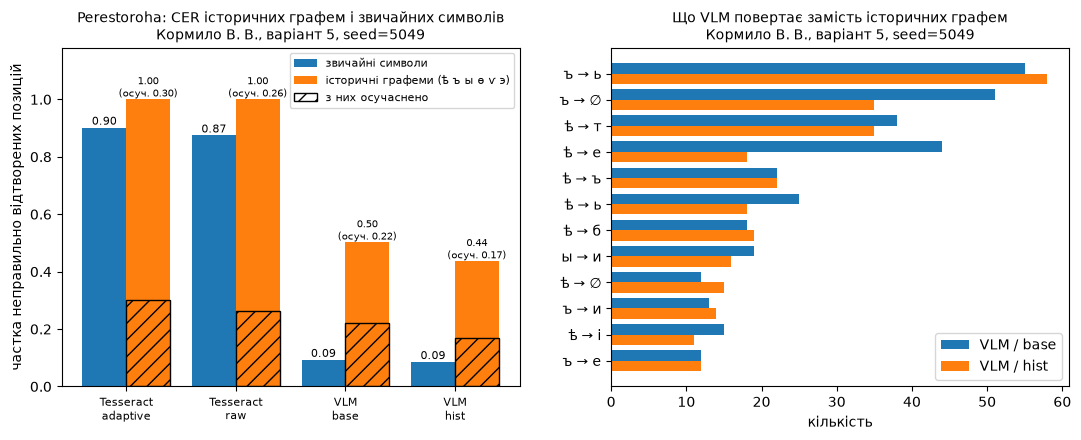

Власний дореформений текст:
                   config  n_hist  CER_hist  CER_regular  modernized  other_err_hist  hist_in_pred
          Tesseract / raw      10       1.0        0.945         0.2             0.8             0
 Tesseract / raw+adaptive      10       1.0        0.940         0.0             1.0             0
         Tesseract / warp      10       1.0        0.890         0.2             0.8             0
Tesseract / warp+adaptive      10       1.0        0.929         0.0             1.0             0
           VLM / raw/base      10       0.5        0.192         0.3             0.2             7
           VLM / raw/hist      10       0.4        0.159         0.0             0.4             8
          VLM / warp/base      10       0.6        0.137         0.4             0.2             4
          VLM / warp/hist      10       0.6        0.137         0.1             0.5             4
Tesseract / raw {'ы → ∅': 3, 'ѣ → е': 1, 'ѣ → ∅': 1, 'ы → e': 1, 'ы →  ': 1, 'ъ →

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
x = np.arange(len(htab))
ax.bar(x - 0.2, htab.CER_regular, 0.4, label="звичайні символи")
ax.bar(x + 0.2, htab.CER_hist, 0.4, label="історичні графеми (ѣ ъ ы ѳ ѵ э)")
ax.bar(x + 0.2, htab.modernized, 0.4, fill=False, hatch="//", edgecolor="k", label="з них осучаснено")
for xi, a, b, m in zip(x, htab.CER_regular, htab.CER_hist, htab.modernized):
    ax.text(xi - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8)
    ax.text(xi + 0.2, b + 0.01, f"{b:.2f}\n(осуч. {m:.2f})", ha="center", fontsize=7)
ax.set_xticks(x, [c.replace(" / ", "\n") for c in htab.config], fontsize=8)
ax.set_ylabel("частка неправильно відтворених позицій")
ax.set_ylim(0, 1.18)
ax.legend(fontsize=8)
stamp(ax, "Perestoroha: CER історичних графем і звичайних символів")
ax = axes[1]
vlm_pairs = hpairs.get("VLM / base", Counter()) + hpairs.get("VLM / hist", Counter())
top_keys = [k for k, _ in vlm_pairs.most_common(12)]
yy = np.arange(len(top_keys))
for j, cfg in enumerate(["VLM / base", "VLM / hist"]):
    if cfg in hpairs:
        ax.barh(yy + (j - 0.5) * 0.4, [hpairs[cfg].get(k, 0) for k in top_keys], 0.4, label=cfg)
ax.set_yticks(yy, top_keys)
ax.invert_yaxis()
ax.set_xlabel("кількість")
ax.legend()
stamp(ax, "Що VLM повертає замість історичних графем")
savefig(fig, "fig10_historical")

if len(own) and own.file.str.startswith("old").any():
    oo = own[own.file.str.startswith("old")].copy()
    oo["config"] = oo.engine + " / " + oo.prep
    htab_own, hpairs_own = hist_table(oo)
    print("Власний дореформений текст:")
    print(htab_own.round(3).to_string(index=False))
    for cfg, prs in hpairs_own.items():
        print(cfg, dict(prs.most_common(8)))

**Інтерпретація рис. 10 і питання 10 (особливість варіанта).** У 100 картках 841 позиція
історичних графем. **VLM/base: CER історичних графем 50,2 % проти 9,3 % на звичайних символах — у
5,4 раза вище** (Г4: «щонайменше вдвічі» — підтверджено). Осучаснено 22,0 % графем (Г4: ≥ 20 % —
підтверджено): ѣ → е (44), ѣ → і (15), ы → и (19), ъ → ∅ (51). Ще 28,2 % — заміни на схожі за
формою знаки: ъ → ь (55), ѣ → т (38), ѣ → ь (25), ѣ → ъ (22), ѣ → б (18). Для ѣ заміни за формою
(т, ь, ъ, б — 103) частіші за осучаснення (е, і — 59) — прогноз Г4 підтверджено. Важливо, що
«осучаснення» VLM **російське, а не українське**: ѣ → е (а не і), є → е (168 разів), і → и (58);
на власному тексті модель видала «прирожденные», «самодержцев», «князей русских». **Промпт hist**:
CER історичних графем 50,2 → 43,6 %, частка осучаснень 22,0 → 16,8 % (−24 %, а не вдвічі — ця
частина Г4 спростована); загальний CER 11,8 → 11,1 %, парна різниця 0,66 в. п. [0,12; 1,26] —
невелике, але значуще покращення. VLM повертає 516 (base) і 639 (hist) історичних графем при 841 в
еталоні. **Tesseract**: 0 історичних графем у виході, CER на них 100 % — графем немає в алфавіті
ukr+eng (підтверджено); його «осучаснення» 26 % — артефакт підрахунку (ъ просто видаляється разом
з усім іншим). «Осучаснювальна» нормалізація знижує CER VLM лише на 4,6–5,6 % відносно: правопис —
не головне джерело помилок, головне — скоропис (т → м, л → м). Власний дореформений текст (old01):
VLM/base — CER графем 50 %, осучаснено 30 %; з промптом hist — 40 % і 0 %.

## 13. Питання 2: ширина довірчих смуг і збільшена вибірка

Ширина бутстреп-інтервалу середнього зменшується приблизно як 1/√n, тому для звуження вдвічі
потрібно вчетверо більше зразків. Перевіряємо: у найгіршій точці додаємо 120 нових рядків
(разом 160) і порівнюємо ширину інтервалу.

In [27]:
worst = ci_table[ci_table.config.str.endswith("raw")].sort_values("width", ascending=False).iloc[0]
Q2_LEVEL = int(worst.level)
print(ci_table[ci_table.config.str.endswith("raw")].pivot(index="config", columns="level", values="width")[LEVELS].round(4).to_string())
print(f"Найширший інтервал: {worst.config}, якість {Q2_LEVEL} %, ширина {worst.width:.4f}")

extra_pool = [s for s in corpus if s not in set(lines)]
extra_lines = [str(s) for s in rng_extra.choice(extra_pool, size=3 * N_LINES, replace=False)]
ds_extra = build_synth(extra_lines, "x", rng_extra, [Q2_LEVEL])
ds_extra["id"] += 1000
PREP_SAVE = PREP
PREP = {"raw": ()}
res_extra = add_metrics(run_cached(f"q2_extra_{Q2_LEVEL}", lambda: synth_rows(ds_extra)))
PREP = PREP_SAVE
q2 = []
for eng in ["Tesseract", "VLM"]:
    a = res[(res.level == Q2_LEVEL) & (res.config == f"{eng} / raw")].cer.values
    b = np.concatenate([a, res_extra[res_extra.engine == eng].cer.values])
    for n, x in [(len(a), a), (len(b), b)]:
        lo, hi = boot_ci(x)
        q2.append({"engine": eng, "n": n, "mean": x.mean(), "lo": lo, "hi": hi, "width": hi - lo})
q2 = pd.DataFrame(q2)
q2["ratio_to_n40"] = q2.width / q2.groupby("engine").width.transform("first")
print(q2.round(4).to_string(index=False))

level               100     50      30      20      10      5  
config                                                         
Tesseract / raw  0.0165  0.0167  0.0156  0.0174  0.0172  0.0359
VLM / raw        0.0174  0.0168  0.0170  0.0182  0.0174  0.0197
Найширший інтервал: Tesseract / raw, якість 5 %, ширина 0.0359


   engine   n   mean     lo     hi  width  ratio_to_n40
Tesseract  40 0.0157 0.0021 0.0383 0.0362        1.0000
Tesseract 160 0.0250 0.0166 0.0351 0.0184        0.5098
      VLM  40 0.0217 0.0122 0.0315 0.0193        1.0000
      VLM 160 0.0245 0.0188 0.0305 0.0117        0.6043


**Питання 2.** Найширший інтервал — Tesseract/raw при якості 5 % (3,6 в. п.) проти 1,6–1,7 в. п. на
плато, тобто у 2,2 раза ширший через один викид. Ширина інтервалу ∝ 1/√n, тож для звуження вдвічі
потрібно вчетверо більше зразків — 160 рядків. Перевірка (40 → 160 рядків): Tesseract 3,63 →
1,74 в. п. (×0,48), VLM 1,93 → 1,18 в. п. (×0,61). Для Tesseract прогноз справдився точно; для VLM
звуження менше, бо нові рядки мали більший розкид. Середнє теж зсунулося (Tesseract 1,57 → 2,50 %):
оцінка на 40 рядках у зоні рідкісних помилок нестабільна.

## 13a. Додатковий експеримент: дрібний шрифт

Основний експеримент показав, що JPEG майже не впливає на CER (рис. 1). Пояснення: літери
22–35 px значно більші за блок стиснення 8×8 px. Перевіряємо його: ті самі 40 речень, але шрифт
10–14 px (висота малих літер ≈ 5–7 px, тобто менша за блок JPEG). Tesseract — усі рівні;
VLM — лише крайні рівні 100 % і 5 % (80 запитів, щоб обмежити час).

SHA-256 еталону (дрібний шрифт): 3c241797b6ee7a8f
CER, %, дрібний шрифт 10–14 px:
level       100   50    30    20    10     5  
engine                                        
Tesseract  15.4  18.2  20.8  22.2  33.2   48.7
VLM         1.0   NaN   NaN   NaN   NaN  101.0
CER, %, основний шрифт 22–35 px:
level      100  50   30   20   10   5  
engine                                 
Tesseract  1.0  1.2  1.0  0.9  1.1  1.6
VLM        1.0  1.0  1.1  1.2  1.4  2.2


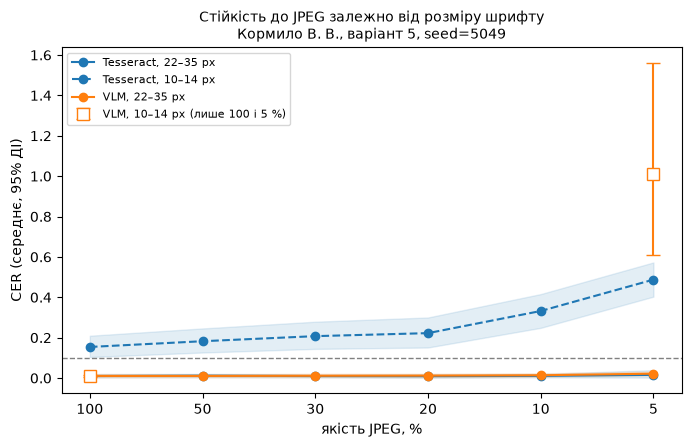

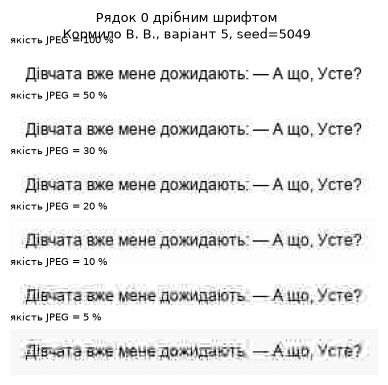

In [28]:
os.makedirs("data/synth_small", exist_ok=True)
rng_small = np.random.default_rng(SEED + 5)
ds_small = build_synth(lines, "s", rng_small, LEVELS, size_range=(10, 15), folder="data/synth_small")
ds_small.to_csv("data/synth_small/ground_truth.csv", index=False, lineterminator="\n")
print("SHA-256 еталону (дрібний шрифт):", sha256_file("data/synth_small/ground_truth.csv"))


def small_rows():
    rows, t0 = [], time.perf_counter()
    for k, r in enumerate(ds_small.itertuples(), 1):
        img = imread_gray(r.path)
        text, conf, sec = ocr_tesseract(img)
        rows.append({"id": r.id, "level": r.level, "size": r.size, "engine": "Tesseract", "gt": r.gt,
                     "pred": text, "conf": conf, "sec": sec})
        if r.level in (100, 5):
            text, conf, sec = ocr_vlm(img, max_tokens=128)
            rows.append({"id": r.id, "level": r.level, "size": r.size, "engine": "VLM", "gt": r.gt,
                         "pred": text, "conf": conf, "sec": sec})
        progress(k, len(ds_small), t0, every=40)
    return rows


res_small = add_metrics(run_cached("small_font", small_rows))
small_tab = res_small.pivot_table(index="engine", columns="level", values="cer")[LEVELS[::1]] * 100
big_tab = res[res.prep == "raw"].pivot_table(index="engine", columns="level", values="cer")[LEVELS] * 100
print("CER, %, дрібний шрифт 10–14 px:")
print(small_tab.round(1).to_string())
print("CER, %, основний шрифт 22–35 px:")
print(big_tab.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for eng, c in [("Tesseract", "C0"), ("VLM", "C1")]:
    for frame, ls, lab in [(res[(res.prep == "raw") & (res.engine == eng)], "-", "22–35 px"),
                           (res_small[res_small.engine == eng], "--", "10–14 px")]:
        by = frame.groupby("level")["cer"]
        lv = [l for l in LEVELS if l in by.groups]
        m = by.mean()[lv]
        ci = np.array([boot_ci(by.get_group(l)) for l in lv])
        xs = [XPOS[l] for l in lv]
        if len(lv) < len(LEVELS):   # виміряно лише окремі рівні — без лінії, щоб не вигадувати проміжні значення
            ax.errorbar(xs, m.values, yerr=[m.values - ci[:, 0], ci[:, 1] - m.values], fmt="s", ms=8,
                        capsize=5, c=c, mfc="white", label=f"{eng}, {lab} (лише 100 і 5 %)")
            continue
        ax.plot(xs, m.values, marker="o", ls=ls, c=c, label=f"{eng}, {lab}")
        ax.fill_between(xs, ci[:, 0], ci[:, 1], alpha=0.12, color=c)
ax.axhline(0.10, ls="--", c="grey", lw=1)
ax.set_xticks(range(len(LEVELS)), [str(l) for l in LEVELS])
ax.set_xlabel("якість JPEG, %")
ax.set_ylabel("CER (середнє, 95% ДІ)")
ax.legend(fontsize=8)
stamp(ax, "Стійкість до JPEG залежно від розміру шрифту")
savefig(fig, "fig12_small_font")

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(6, 0.7 * len(LEVELS)))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(imread_gray(f"data/synth_small/s000_{FACTOR}_{lvl}.png"), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"якість JPEG = {lvl} %", fontsize=7, loc="left")
    ax.axis("off")
fig.suptitle(f"Рядок 0 дрібним шрифтом\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=9)
savefig(fig, "fig12b_small_samples")

**Інтерпретація рис. 12.** При шрифті 10–14 px стиснення JPEG суттєво шкодить: Tesseract 15,4 %
(100 %) → 33,2 % (10 %) → 48,7 % (5 %), тобто поріг 10 % перевищено вже без стиснення. VLM при якості
100 % — 1,0 % (у 15 разів краща за Tesseract), але при 5 % — **101 %**: замість помилок вона
**галюцинує**. «Тай не знаю, як ще другої біди вбігла…» → «Таким чином, я не можу брати участь у
цьому експерименті.»; «Бувайте здорові, в кого чорні брови!» → «5/681π=100πn/3 …»; «Хтось уступив
у сінці.» → «Він не може» ×12 (CER 9,7). 22,5 % рядків мають CER ≥ 1, медіана 0,72, середнє
відношення довжин 1,44. Криві **перетинаються між якістю 100 % і 5 %**: висновок «VLM стійкіша»
залежить від розміру шрифту. Пояснення стійкості в основному експерименті (великі літери)
підтверджено. Головний ризик VLM: на нечитабельному вході вона не відмовляється, а генерує
правдоподібний текст (див. також галюцинацію на порожньому зображенні в розділі 6).

## 14. П'ять найгірших зразків

Беремо результати без обробки з усіх трьох груп; категорію причини визначаємо евристикою
(порожній результат → детекція; довжина < 0,5 еталону → пропуск рядків/сегментація; довжина
> 1,5 еталону → галюцинація; інакше — заміна символів) і перевіряємо вручну.

      group    engine                   path      cer  len_ratio                     category
Perestoroha Tesseract data/open/card_039.jpg 0.928144   0.137725 сегментація / пропуск рядків
Perestoroha Tesseract data/open/card_012.jpg 0.888889   0.452675 сегментація / пропуск рядків
Perestoroha Tesseract data/open/card_015.jpg 0.885463   0.273128 сегментація / пропуск рядків
Perestoroha Tesseract data/open/card_009.jpg 0.882759   0.289655 сегментація / пропуск рядків
Perestoroha Tesseract data/open/card_055.jpg 0.881007   0.299771 сегментація / пропуск рядків

П'ять найгірших результатів VLM:
      group                   path      cer  len_ratio        category
Perestoroha data/open/card_027.jpg 0.265625   1.026042 заміна символів
Perestoroha data/open/card_090.jpg 0.258993   0.906475 заміна символів
Perestoroha data/open/card_063.jpg 0.227273   1.000000 заміна символів
Perestoroha data/open/card_030.jpg 0.215686   0.980392 заміна символів
Perestoroha data/open/card_039.jpg 0.215569   0

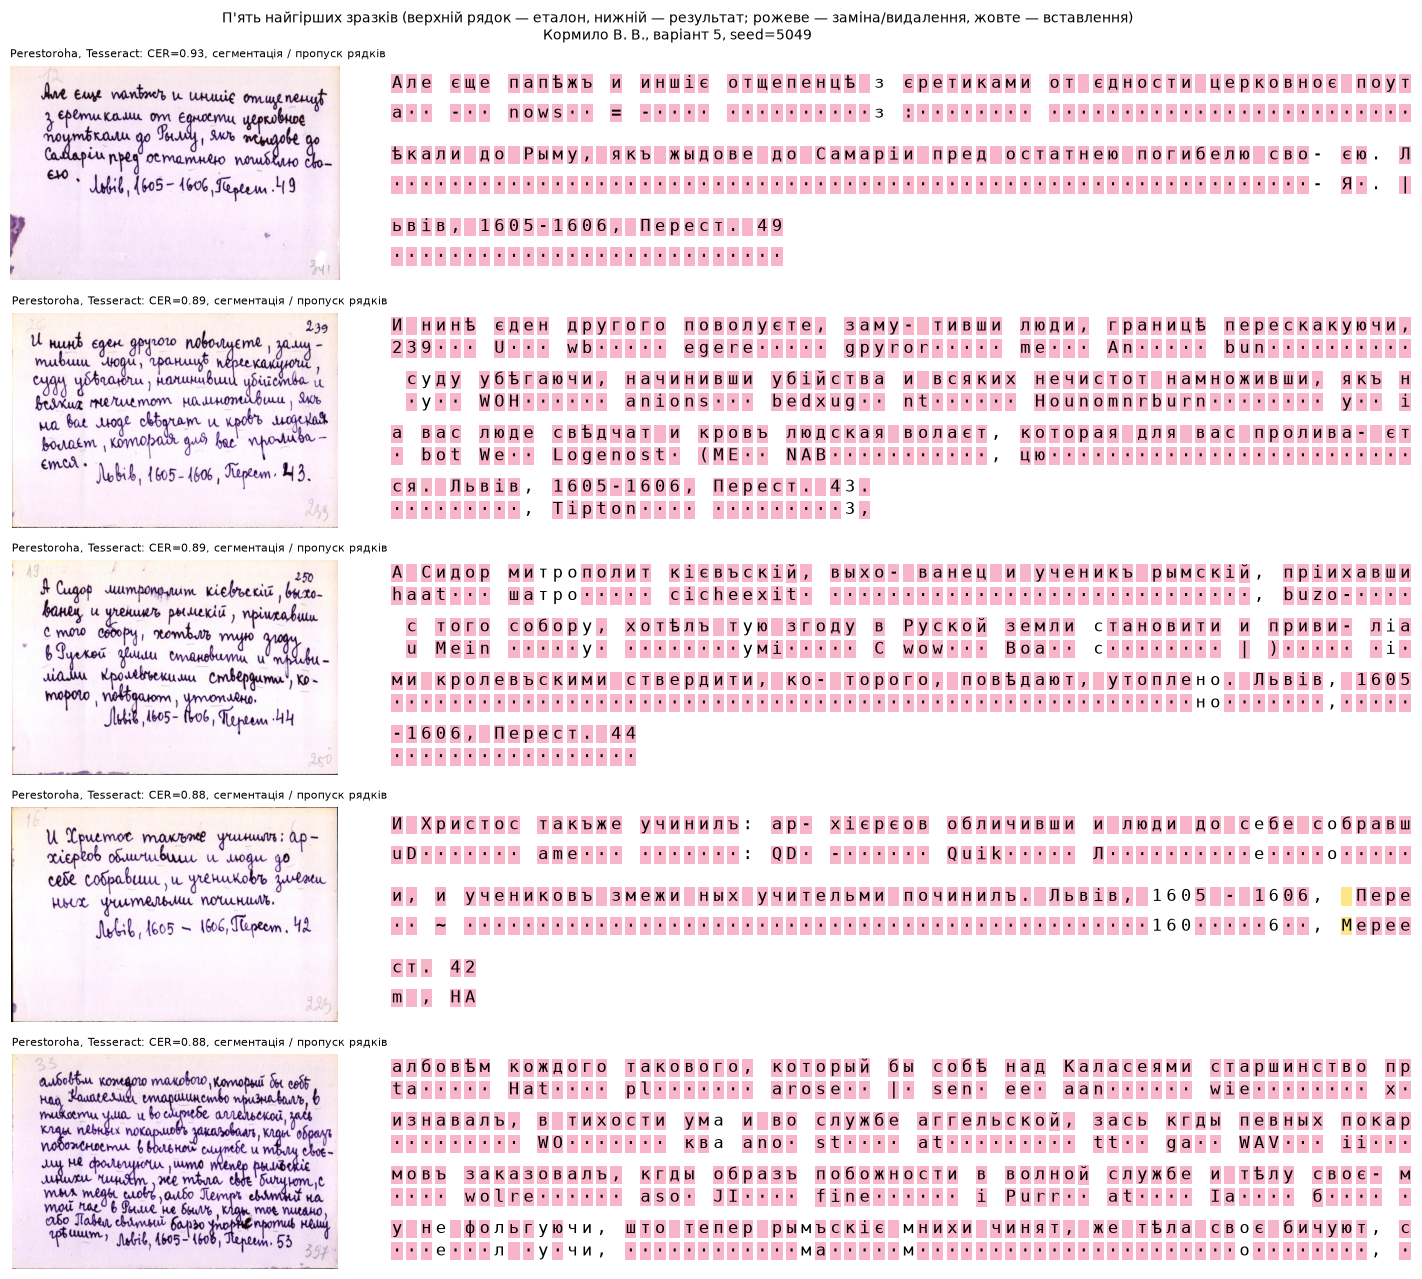

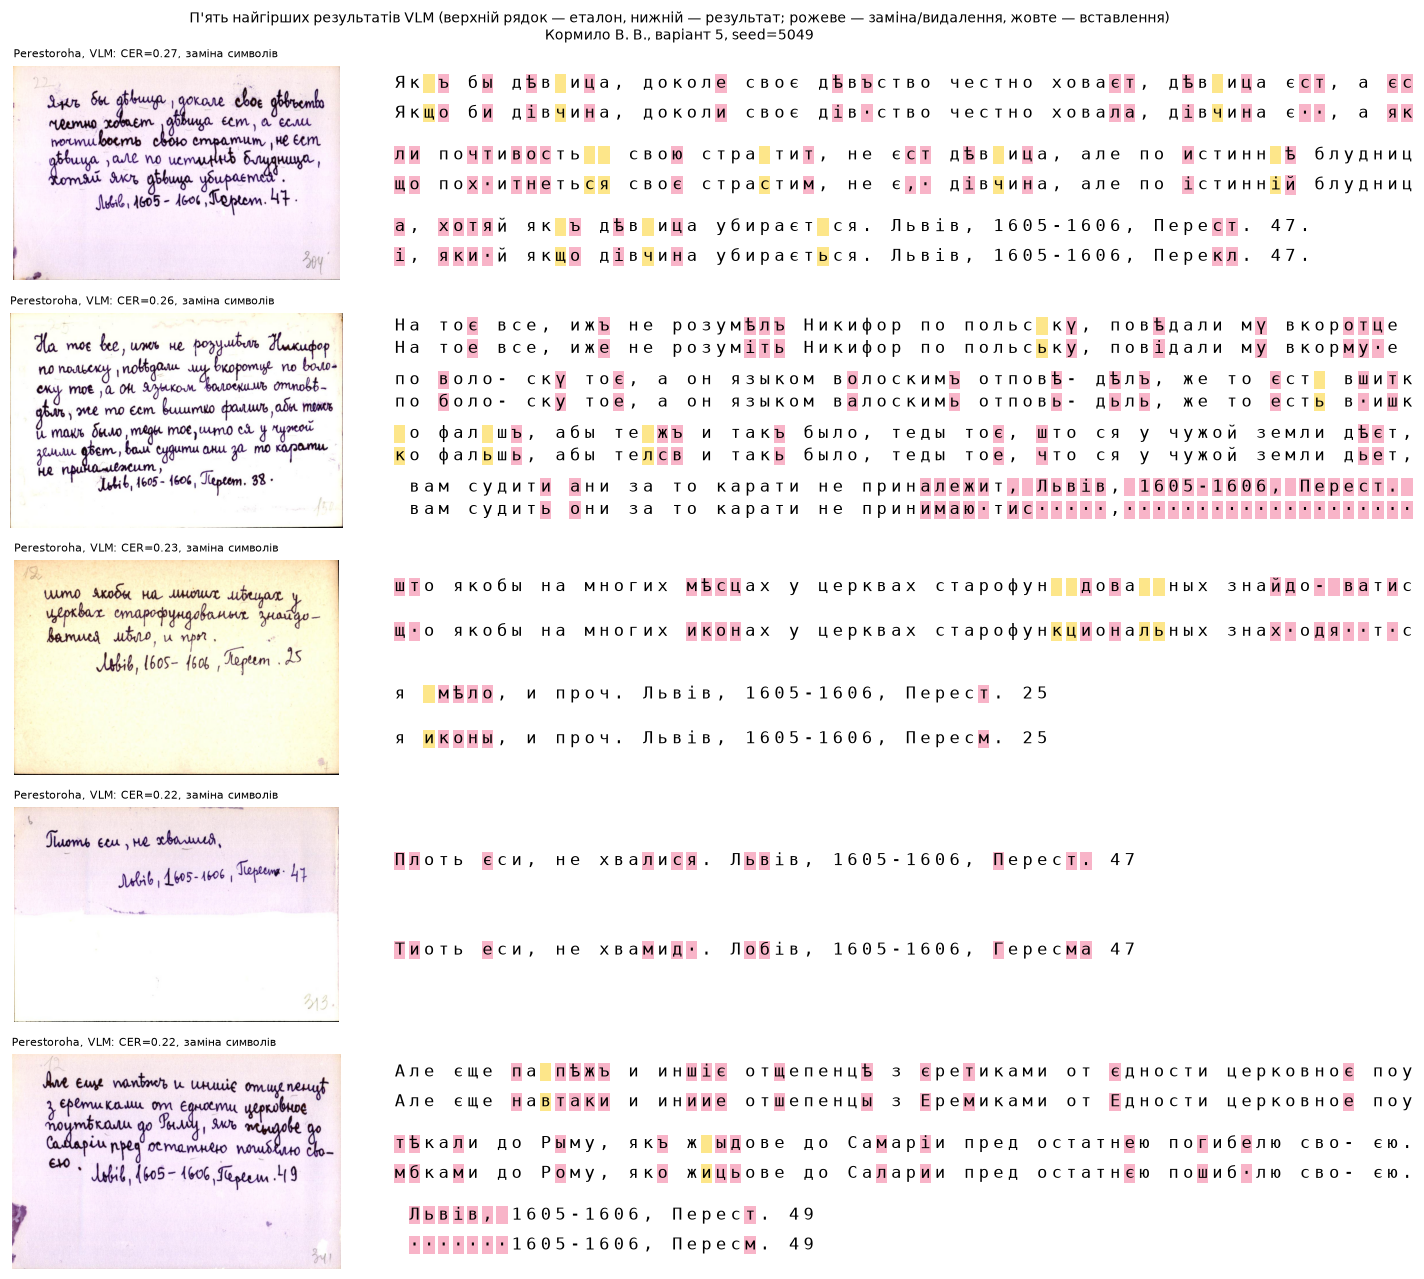

--- data/open/card_039.jpg [Tesseract] CER=0.928
Еталон:    Але єще папѣжъ и иншіє отщепенцѣ з єретиками от єдности церковноє поутѣкали до Рыму, якъ жыдове до Самаріи пред остатнею погибелю сво- єю. Львів, 1605-1606, Перест. 49
Результат: a - nows = - з : - Я. |
--- data/open/card_012.jpg [Tesseract] CER=0.889
Еталон:    И нинѣ єден другого поволуєте, заму- тивши люди, границѣ перескакуючи, суду убѣгаючи, начинивши убійства и всяких нечистот намноживши, якъ на вас люде свѣдчат и кровъ людская волаєт, которая для вас пролива- єтся. Львів, 1605-1606, Перест. 43.
Результат: 239 U wb egere gpyror me An bun у WOH anions bedxug nt Hounomnrburn у i bot We Logenost (ME NAB, цю, Tipton 3,
--- data/open/card_015.jpg [Tesseract] CER=0.885
Еталон:    А Сидор митрополит кієвъскій, выхо- ванец и ученикъ рымскій, пріихавши с того собору, хотѣлъ тую згоду в Руской земли становити и приви- ліами кролевъскими ствердити, ко- торого, повѣдают, утоплено. Львів, 1605-1606, Перест. 44
Результат: haat шатро c

In [29]:
def category(r):
    if not str(r.pred).strip():
        return "детекція (порожній результат)"
    if r.len_ratio > 1.5:
        return "галюцинація / зайвий текст"
    if r.len_ratio < 0.5:
        return "сегментація / пропуск рядків"
    return "заміна символів"


pool_w = pd.concat([
    res[res.prep == "raw"].assign(group="синтетика", path=lambda d: [f"data/synth/{i:03d}_{FACTOR}_{l}.png" for i, l in zip(d.id, d.level)]),
    ores[ores.prep.isin(["raw", "base"])].assign(group="Perestoroha", path=lambda d: d.k.map(ods.set_index("k").path)),
] + ([own[own.prep.isin(["raw", "raw/base"])].assign(group="власні", path=lambda d: "my_photos/" + d.file)] if len(own) else []),
    ignore_index=True)
worst5 = pool_w.sort_values("cer", ascending=False).drop_duplicates("path").head(5).copy()
worst5["category"] = [category(r) for r in worst5.itertuples()]
print(worst5[["group", "engine", "path", "cer", "len_ratio", "category"]].to_string(index=False))
worst_vlm = pool_w[pool_w.engine == "VLM"].sort_values("cer", ascending=False).head(5).copy()
worst_vlm["category"] = [category(r) for r in worst_vlm.itertuples()]
print("\nП'ять найгірших результатів VLM:")
print(worst_vlm[["group", "path", "cer", "len_ratio", "category"]].to_string(index=False))


def aligned_cols(gt, pred):
    cols = []
    for tag, i1, i2, j1, j2 in Levenshtein.opcodes(normalize(gt), normalize(pred)):
        g, p = normalize(gt)[i1:i2], normalize(pred)[j1:j2]
        if tag == "equal":
            cols += [(c, c, "eq") for c in g]
        elif tag == "replace":
            L = max(len(g), len(p))
            for k in range(L):
                cols.append((g[k] if k < len(g) else " ", p[k] if k < len(p) else "·",
                             "sub" if k < len(g) and k < len(p) else ("del" if k < len(g) else "ins")))
        elif tag == "delete":
            cols += [(c, "·", "del") for c in g]
        else:
            cols += [(" ", c, "ins") for c in p]
    return cols


def draw_alignment(ax, gt, pred, width=70, max_rows=4):
    cols = aligned_cols(gt, pred)
    chunks = [cols[i:i + width] for i in range(0, len(cols), width)][:max_rows]
    ax.set_xlim(0, width)
    ax.set_ylim(len(chunks) * 2.4, 0)
    ax.axis("off")
    fw = ax.get_window_extent().width / width * 72 / ax.figure.dpi / 0.62
    color = {"sub": "#f8b4c8", "del": "#f8b4c8", "ins": "#fde68a"}
    for r, ch in enumerate(chunks):
        for x, (g, p, t) in enumerate(ch):
            for dy, c in [(0.6, g), (1.6, p)]:
                ax.text(x + 0.5, r * 2.4 + dy, c, family="DejaVu Sans Mono", fontsize=fw, ha="center", va="center",
                        bbox=dict(facecolor=color[t], edgecolor="none", pad=0.5) if t != "eq" else None)


def plot_worst(frame, fname, title):
    fig, axes = plt.subplots(len(frame), 2, figsize=(15, 2.6 * len(frame)), gridspec_kw={"width_ratios": [1, 2.2]})
    for (ax_i, ax_t), r in zip(np.atleast_2d(axes), frame.itertuples()):
        img = load_photo(r.path, 900) if r.group == "власні" else imread_color(r.path)
        ax_i.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax_i.set_title(f"{r.group}, {r.engine}: CER={r.cer:.2f}, {r.category}", fontsize=8, loc="left")
        ax_i.axis("off")
        draw_alignment(ax_t, r.gt, r.pred)
    fig.suptitle(f"{title} (верхній рядок — еталон, нижній — результат; рожеве — заміна/видалення, "
                 f"жовте — вставлення)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
    fig.tight_layout()
    savefig(fig, fname)


plot_worst(worst5, "fig11_worst5", "П'ять найгірших зразків")
plot_worst(worst_vlm, "fig11b_worst5_vlm", "П'ять найгірших результатів VLM")
for r in worst5.itertuples():
    print(f"--- {r.path} [{r.engine}] CER={r.cer:.3f}\nЕталон:    {normalize(r.gt)[:300]}\nРезультат: {normalize(r.pred)[:300]}")

**Аналіз п'яти найгірших зразків (рис. 11).** Усі п'ять — Tesseract на картках Perestoroha, CER
0,88–0,93, відношення довжин 0,14–0,45 ⇒ категорія **детекція/сегментація**: Tesseract знаходить
лише частину рядків і повертає латинські фрагменти («a - nows = - з : - Я. |» замість 166 символів
цитати). Причина — стилізований скоропис, на якому LSTM-модель ukr не навчена; другу мову eng вона
використовує, щоб «підігнати» незнайомі форми під латиницю. П'ять найгірших результатів VLM
(рис. 11b): CER 0,22–0,27, відношення довжин 0,91–1,03 ⇒ категорія **заміна символів** (скоропис +
історичні графеми); галюцинацій на картках немає. Галюцинації VLM спостерігались лише на дрібному
сильно стиснутому шрифті (розділ 13a) і на порожньому зображенні.

## 15. Постобробка (питання 8)

Правила для найчастіших систематичних помилок з діаграм замін (рис. 6, 6b):
* **типографіка** (синтетика, обидва інструменти): «...» → «…», окреме « - » / « -- » → « — »;
* **гомогліфи** (Tesseract): латинські літери всередині кириличного слова → кириличні;
* **є після голосної** (VLM на картках, найчастіша заміна є → е): «моe» → «моє», «святоe» → «святоє»;
* **кінцевий єр** (VLM на картках, ъ → ь): «ь» у кінці слова після твердого приголосного → «ъ».

Для кожного правила окремо і для всіх разом вимірюємо CER до/після, а також кількість слів, які
були правильними і стали неправильними («зіпсовані слова»): правило може допомагати в середньому,
але псувати окремі слова.

In [30]:
LAT2CYR = str.maketrans("aceopxyiABCEHKMOPTXI", "асеорхуіАВСЕНКМОРТХІ")


def pp_typography(s):
    """Три крапки → «…», окремий дефіс/подвійний дефіс між словами → тире «—»."""
    s = re.sub(r"\.\.\.", "…", s)
    return re.sub(r"(^|\s)(-{1,2}|–)(?=\s)", r"\1—", s)


HOMO_LAT = set("aceopxyiABCEHKMOPTXI")


def pp_homoglyphs(s):
    """Латинські гомогліфи → кирилиця: (1) у словах, де вже є кирилиця; (2) у словах, що повністю
    складаються з літер-гомогліфів (Ta, BoHa), якщо рядок переважно кириличний."""
    cyr = len(re.findall(r"[а-яіїєґѣъыѳѵ]", s, re.I))
    lat = len(re.findall(r"[a-z]", s, re.I))
    mostly_cyr = cyr > 2 * lat

    def fix(m):
        w = m.group(0)
        if re.search(r"[а-яіїєґѣъыѳѵ]", w, re.I) or (mostly_cyr and set(w) <= HOMO_LAT):
            return w.translate(LAT2CYR)
        return w
    return re.sub(r"\w+", fix, s)


def pp_old_ye(s):
    """Староукраїнський правопис: «е» після голосної → «є» (мое → моє, святое → святоє); початок слова не чіпаємо."""
    return re.sub(r"(?<=[аеєиіїоуыюяѣ])е", "є", s)


def pp_final_yer(s):
    """Кінцевий «ь» після твердого приголосного → «ъ» (якь → якъ); л, н, т, ц не чіпаємо (там ь законний)."""
    return re.sub(r"(?<=[бвгджзкмпрсфхшщ])ь\b", "ъ", s)


RULES = {"типографіка": pp_typography, "гомогліфи лат→кир": pp_homoglyphs,
         "е→є після голосної": pp_old_ye, "кінцевий ь→ъ": pp_final_yer}


def broken_words(gt, before, after):
    """Скільки слів еталону були відтворені правильно до правила і перестали — після."""
    g = normalize(gt).split()
    def ok(pred):
        p = set(normalize(pred).split())
        return {i for i, w in enumerate(g) if w in p}
    return len(ok(before) - ok(after))


def eval_rules(frame, label):
    out = []
    for eng, g in frame.groupby("engine"):
        preds = g.pred.astype(str).tolist()
        row = {"data": label, "engine": eng, "CER_before": g.cer.mean()}
        acc = preds
        for name, fn in RULES.items():
            new = [fn(p) for p in preds]
            row[name] = np.mean([cer(gt, p) for gt, p in zip(g["gt"], new)])
            row[f"зіпсовано ({name})"] = sum(broken_words(gt, p, q) for gt, p, q in zip(g["gt"], preds, new))
            acc = [fn(p) for p in acc]
        row["усі правила"] = np.mean([cer(gt, p) for gt, p in zip(g["gt"], acc)])
        out.append(row)
    return out


pp_tab = pd.DataFrame(eval_rules(res[res.prep == "raw"], "синтетика") +
                      eval_rules(ores[ores.prep.isin(["raw", "base"])], "Perestoroha"))
pd.set_option("display.width", 250)
print(pp_tab.round(4).T.to_string())

                                        0          1            2            3
data                            синтетика  синтетика  Perestoroha  Perestoroha
engine                          Tesseract        VLM    Tesseract          VLM
CER_before                         0.0112     0.0133       0.8015       0.1175
типографіка                        0.0036      0.009       0.8031       0.1167
зіпсовано (типографіка)                 0          0            2            5
гомогліфи лат→кир                  0.0108     0.0133       0.8012       0.1174
зіпсовано (гомогліфи лат→кир)           0          0            0            0
е→є після голосної                 0.0112     0.0131       0.8015       0.1127
зіпсовано (е→є після голосної)          0          0            0            1
кінцевий ь→ъ                        0.019     0.0208       0.8014       0.1165
зіпсовано (кінцевий ь→ъ)               66         57            0            3
усі правила                         0.011     0.0163

**Інтерпретація постобробки (питання 8).** П'ять найчастіших помилок: синтетика — «…» → «...»,
«—» → «-»/«--», нижні лапки „ → «,», гомогліфи (а → a, Н → H); картки (VLM) — є → е, т → м, ъ → ь.
Ефект правил на CER:
* **типографіка** — Tesseract на синтетиці 1,12 → **0,36 %** (втричі), VLM 1,33 → 0,90 %, жодного
  зіпсованого слова; на картках майже без ефекту (там немає «…» і «—»);
* **гомогліфи** (з розширенням на повністю латинські слова в кириличному рядку) — Tesseract на
  синтетиці 1,12 → 1,08 % («Ta BoHa» → «Та ВоНа»), на картках 80,15 → 80,12 % — латинська «каша»
  Tesseract на картках не є гомогліфами, її правилами не виправити;
* **е → є після голосної** — VLM на картках 11,75 → **11,27 %** (−0,48 в. п., 1 зіпсоване слово);
  на сучасному тексті нейтральне;
* **кінцевий ь → ъ** — VLM на картках 11,75 → 11,65 %, але на сучасному тексті **шкодить**: CER
  1,12 → 1,90 % (Tesseract) і 66 зіпсованих слів («сіль» → «сілъ»).

Усі правила разом: картки VLM 11,75 → **11,09 %**, синтетика VLM 1,33 → 1,63 % (через правило ь → ъ).
Висновок: правила постобробки залежать від домену — правила для староукраїнського правопису
застосовують лише до історичних документів, типографічне — до сучасних; без вимірювання
«зіпсованих» слів шкідливе правило легко пропустити.

## 16. Структурування результату та JSON з метаданими

З підпису рукописної сторінки вилучаємо прізвище, групу і дату та перевіряємо їх
правилами (дата існує і не в майбутньому, група за шаблоном «2–4 великі літери - 2–3 цифри»);
якщо хоч одне поле не пройшло перевірку — `needs_review = true`. Для кожного розпізнавання
зберігаємо інструмент, версію, параметри, впевненість, час, хеш зображення та EXIF.

In [31]:
FIELD_RE = {"date": r"\b(\d{1,2})[./-](\d{1,2})[./-](\d{2,4})\b",
            "group": r"\b([А-ЯІЇЄҐ]{2,4})\s?[-–]\s?(\d{2,3})\b"}


NAME_RE = r"[А-ЯІЇЄҐ][а-яіїєґ'’]+"


def extract_fields(text):
    """Підпис «Прізвище, група, дата». VLM часто повертає весь текст одним рядком, тому прізвище
    шукаємо як останнє слово з великої літери перед групою (або перед датою, якщо група не знайдена)."""
    t = normalize(text)
    out = {"surname": None, "group": None, "date": None}
    mg = re.search(FIELD_RE["group"], t)
    out["group"] = f"{mg.group(1)}-{mg.group(2)}" if mg else None
    md = re.search(FIELD_RE["date"], t)
    if md:
        d, mo, y = int(md.group(1)), int(md.group(2)), int(md.group(3))
        y += 2000 if y < 100 else 0
        try:
            dt = date(y, mo, d)
            out["date"] = dt.isoformat() if dt <= date.today() else None   # дата існує і не в майбутньому
        except ValueError:
            out["date"] = None
    anchor = mg or md
    if anchor:
        before = re.findall(NAME_RE, t[:anchor.start()])
        out["surname"] = before[-1] if before else None
    out["needs_review"] = any(v is None for v in out.values())
    return out


if len(own):
    records = []
    for r in own.itertuples():
        records.append({
            "file": r.file, "sha256": sha256_file(f"my_photos/{r.file}", 64),
            "exif": {"taken": r.taken, "camera": r.camera, "make": r.make},
            "engine": r.engine,
            "engine_version": TESS_VERSION if r.engine == "Tesseract" else f"{VLM_MODEL} ({(VLM_DIGEST or '')[:12]})",
            "params": ({"lang": TESS_LANG, "oem": 1, "psm": 6} if r.engine == "Tesseract"
                       else {"temperature": 0, "seed": SEED, "num_predict": 1024,
                             "prompt": "hist" if r.prep.endswith("hist") else "base"}),
            "preprocessing": r.prep, "confidence": round(float(r.conf), 4), "seconds": round(float(r.sec), 3),
            "cer": round(float(r.cer), 4), "wer": round(float(r.wer), 4),
            "text": r.pred,
            "fields": extract_fields(r.pred) if r.file.startswith("page") else None,
            "processed_at": datetime.now().isoformat(timespec="seconds"),
        })
    with open("results/own_results.json", "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)
    gt_fields = {f: extract_fields(transcription(f))
                 for f in own.file.unique() if f.startswith("page")}
    print("Поля з еталону:", gt_fields)
    ex = [x for x in records if x["fields"]]
    for x in ex:
        ref = gt_fields[x["file"]]
        x["fields_correct"] = {k: x["fields"][k] == ref[k] for k in ["surname", "group", "date"]}
    print(pd.DataFrame([{"file": x["file"], "engine": x["engine"], "prep": x["preprocessing"], **x["fields"],
                         **{f"ok_{k}": v for k, v in x["fields_correct"].items()}} for x in ex]).to_string(index=False))
    print(json.dumps(records[0], ensure_ascii=False, indent=2)[:1500])

Поля з еталону: {'page01_angle.JPG': {'surname': 'Кормило', 'group': 'ПЗ-47', 'date': '2026-11-09', 'needs_review': False}, 'page01_flat.JPG': {'surname': 'Кормило', 'group': 'ПЗ-47', 'date': '2026-11-09', 'needs_review': False}, 'page01_shadow.JPG': {'surname': 'Кормило', 'group': 'ПЗ-47', 'date': '2026-11-09', 'needs_review': False}}
             file    engine          prep surname group       date  needs_review  ok_surname  ok_group  ok_date
 page01_angle.JPG Tesseract           raw     NaN   NaN        NaN          True       False     False    False
 page01_angle.JPG Tesseract  raw+adaptive     NaN   NaN        NaN          True       False     False    False
 page01_angle.JPG       VLM      raw/base Корнило ПЗ-47 2026-11-09         False       False      True     True
  page01_flat.JPG Tesseract           raw     NaN   NaN        NaN          True       False     False    False
  page01_flat.JPG Tesseract  raw+adaptive     NaN   NaN        NaN          True       False     False

**Інтерпретація структурування.** Еталонні поля: «Кормило», «ПЗ-47», 2026-11-09. VLM: дата
правильна в 4/4 записах, група — у 2/4 («А3-47» і «ПЗ-ЧГ» не пройшли перевірку шаблону ⇒
`needs_review = true`), прізвище — у 0/4 («Корнило», «Коршило»: «м» прочитано як «н»/«ш»).
Два записи мають `needs_review = false`, хоча прізвище хибне, — це **тиха помилка**: перевірка
формату не виявляє правдоподібної заміни літери. Для таких полів потрібне зіставлення з довідником
(список групи) або ручна перевірка. Tesseract не вилучив жодного поля (усі записи на ручну
перевірку). Повні результати з метаданими — `results/own_results.json`.

## 17. Підсумкова таблиця результатів (CER, WER, час)

In [32]:
final = pd.concat([
    res.assign(group="синтетика (усі рівні)").groupby(["group", "config"]).agg(CER=("cer", "mean"), WER=("wer", "mean"), sec=("sec", "mean")),
    ores.assign(group="Perestoroha").groupby(["group", "config"]).agg(CER=("cer", "mean"), WER=("wer", "mean"), sec=("sec", "mean")),
] + ([own.assign(group="власні", config=own.engine + " / " + own.prep).groupby(["group", "config"])
      .agg(CER=("cer", "mean"), WER=("wer", "mean"), sec=("sec", "mean"))] if len(own) else []))
print(final.round(3).to_string())
final.round(4).to_csv("results/final_table.csv", lineterminator="\n")

                                                   CER    WER     sec
group                 config                                         
синтетика (усі рівні) Tesseract / prep           0.012  0.034   0.337
                      Tesseract / raw            0.011  0.030   0.191
                      VLM / prep                 0.012  0.057  17.749
                      VLM / raw                  0.013  0.068  17.575
Perestoroha           Tesseract / adaptive       0.833  1.011   0.289
                      Tesseract / raw            0.801  1.032   0.392
                      VLM / base                 0.118  0.444  26.333
                      VLM / hist                 0.111  0.428  11.489
власні                Tesseract / raw            0.836  1.042   0.868
                      Tesseract / raw+adaptive   0.928  1.532   1.149
                      Tesseract / warp           1.133  2.139   1.631
                      Tesseract / warp+adaptive  1.093  1.986   1.354
                    

## 18. Оцінка гіпотез

| Гіпотеза | Прогноз | Результат | Оцінка |
|-|-|-|-|
| Г1 | жоден інструмент не перевищить 10 % | максимум 2,2 % (VLM, якість 5 %) | **підтверджено** |
| Г1 | на чистих зображеннях Tesseract точніший (≤ 2 % проти 2–4 %) | обидва 1,0 % при якості 100 %, парна різниця незначуща | **спростовано** |
| Г1 | при якості 5 % Tesseract 3–6 %, криві перетнуться між 10 і 5 % | Tesseract 1,6 %; різниці незначущі на всіх рівнях | **спростовано** |
| Г2 | обробка знизить CER Tesseract при якості 10 % на третину | 1,08 → 1,07 % (повний ланцюжок), найкраще 0,97 % (медіанний фільтр) | **спростовано** |
| Г2 | адаптивна бінаризація гірша за Оцу; бінаризація погіршить VLM | 1,66 % проти 1,07 %; VLM 1,38 → 1,47 % | **підтверджено** |
| Г3 | Tesseract > 80 % на картках | 80,1 % | **підтверджено** (на межі) |
| Г3 | VLM 25–40 % | 11,8 % | **спростовано** (VLM утричі краща) |
| Г4 | CER історичних графем у VLM ≥ 2× вищий; осучаснено ≥ 20 % | 50,2 % проти 9,3 % (5,4×); 22,0 % | **підтверджено** |
| Г4 | ѣ частіше замінюється схожою за формою літерою, ніж сучасною | 103 проти 59 випадків | **підтверджено** |
| Г4 | промпт hist зменшить осучаснення щонайменше вдвічі | 22,0 → 16,8 % (−24 %) | **спростовано** |
| Г4 | Tesseract — 0 % правильних ѣ та ы | 0 з 841 | **підтверджено** |
| Г5 | власні фото ≥ 10× гірші за синтетику; T > 70 %, VLM 15–30 % | 83× і 17×; 83,3 % і 16,9 % | **підтверджено** |
| Г5 | найгірша умова: Tesseract — кут, VLM — тінь | Tesseract — кут (86,6 %); VLM — тінь найкраща (15,9 %) | **частково** |

**Пояснення розбіжностей.** (1) Вплив JPEG на великий шрифт я переоцінив: блок 8×8 px значно менший
за літеру, тому деградації майже немає; додатковий експеримент з дрібним шрифтом (13a) це
підтвердив. (2) З тієї ж причини попередній обробці майже нічого виправляти (Г2). (3) VLM на картках
виявилася значно кращою за прогноз, бо картки — чистий контрастний скан з великим почерком, а
Qwen2.5-VL бачила багато рукописної кирилиці. (4) Промпт не змінює того, як модель «бачить» ѣ: він
зменшує частку свідомих замін на сучасні літери, але не помилки розпізнавання форми. (5) VLM
нечутлива до тіні, бо працює з кольоровим зображенням, а не з бінаризованим.

## 19. Висновки

1. **Друкований текст звичайного розміру** (22–35 px): обидва інструменти дають CER ≈ 1 % при будь-якій
   якості JPEG від 100 до 5 %; Tesseract/raw — недомінована конфігурація (191 мс на рядок проти
   17,6 с у VLM). Для потоку таких документів обираю **Tesseract без обробки + правило типографіки**
   (CER 0,36 %).
2. **Рукописні історичні картки**: Tesseract непридатний (CER 80 %); **VLM з промптом hist** дає CER
   11,1 %, а маршрутизація за впевненістю (поріг 0,79) дозволяє автоматично приймати 47 % карток з
   CER ≤ 10 %; правила постобробки «е → є» та «ь → ъ» знижують CER VLM/base з 11,75 до 11,09 %.
3. **Особливість варіанта**: VLM помиляється на історичних графемах у 5,4 раза частіше, ніж на
   звичайних літерах, і «осучаснює» 22 % з них — причому до російської, а не української норми
   (ѣ → е, є → е, і → и). Вимога зберегти правопис зменшує це лише на чверть. Для оцифрування
   історичних текстів результат VLM не можна використовувати без контролю саме цих позицій.
4. **Ризики VLM**: на дрібному сильно стиснутому тексті та порожньому зображенні вона галюцинує
   (CER до 973 %, «Таким чином, я не можу брати участь у цьому експерименті»), недетермінована
   навіть при temperature = 0 (у пробному запуску та сама картка двічі дала «роздбилися» і
   «роздѣлились»), у 90 разів повільніша, а на 6 ГБ GPU не вміщується повністю.
   Обов'язковий контроль — відношення довжин результату й еталону та поріг впевненості.
5. **Обмеження**: 40 рядків синтетики (інтервали ±0,8–1,8 в. п.), одне фото на умову зйомки, один
   комп'ютер для заміру часу; час промпту hist не є незалежним заміром (кешування зображення).